# Convolutional Neural Network for facial recognition 🚪😛

<div style="font-size: 0.6em">

**Background**

| Part | Model | Purpose |
|---|---|---|
| 1 | RNN + Logistic Regression | Author bot: names which of three authors wrote a sentence |
| 2 | Logistic Regression (from scratch) | Predicts which books become bestsellers |
| **3** | **CNN (TensorFlow)** | **Recognises staff at the company's premises** |

**Dataset:** [Pins Face Recognition](https://www.kaggle.com/hereisburak/pins-face-recognition) (Kaggle) · 105 people · 17,534 images · one folder per person (`pins_<Name>/`), and the folder name is the label

**Environment:** WSL2 Ubuntu · conda `authorbot` (Python 3.10) · TensorFlow 2.15.1 · NumPy 1.26 · RTX 5060 (8 GB) · VS Code + Jupyter

**Scope**
1. Train a CNN to recognise **75 people** (stand-ins for staff).
2. Remove the name picker; the layer before it gives a **128-number face fingerprint**.
3. **Enrol** new staff by saving their fingerprint in a gallery, with **no retraining**.
4. **At the door**, a close match is welcomed and anyone else is sent to reception.
5. **30 people are held back** to prove it works on faces it has never seen.

**Notes and findings**
- 13-11-2026: Planning, Imports, Download & inspect data 
- 14-11-2026: EDA
- 15-11-2026: EDA
- 16-11-2026: Data preprocessing PART 1 & 2
- 17-11-2026: Build CNN + FIX 1 & 2
- 18-11-2026: 'Door' settings + using CNN + error analysis
- 19-11-2026: FINAL CHECKS


</div>

#### Imports and where we use them 
---
###### All imports we selected through planning | Extra imports added here through iterations
###### Also check Tensorflow / GPU and set up helpers for EDA


In [1]:
import os, json, hashlib, random, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hide TensorFlow's log messages (must come BEFORE TensorFlow is imported)
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import imagehash
from PIL import Image
from tqdm.auto import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 72   # smaller on-screen plots so GitHub can display the notebook
%config InlineBackend.figure_formats = ["jpeg"]   # plots shown as JPEG so GitHub can display the notebook (figures/ stays PNG)
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 60}}   # lighter JPEGs
GREEN, GREY = "#4E8A4E", "#8C8C8C" 

print("numpy ", np.__version__)
print("pandas", pd.__version__)
print("opencv", cv2.__version__)

2026-11-20 10:02:46.388972: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-20 10:02:46.389064: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-20 10:02:46.393322: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


numpy  1.26.4
pandas 2.3.3
opencv 4.11.0


###### `cv2` (OpenCV) is the main image tool in this notebook: it loads photos as pixel arrays (in BGR colour order, so they are converted to RGB before display), resizes them, measures brightness, contrast and sharpness in E4, and runs the Haar-cascade face detector in E8. `PIL.Image` (Pillow) opens every file in E1 to confirm it is a real, readable image and to read its size, format and colour mode. `imagehash` gives each photo a perceptual hash, a 64-bit summary of its overall light-and-dark pattern, which E6 compares to find near-duplicate photos, while `hashlib` creates MD5 hashes of the raw file bytes to find exact copies. `tqdm.auto` adds progress bars to the loops that open all ~17,500 images, and `json` saves and reloads the person-level split (`splits.json`) so the same people stay in the test group on every run.

##### Check TensorFlow and GPU
###### EDA doesn't need the GPU, but training later does. If this says *no GPU*, fix it now (wrong kernel, or the `authorbot` environment isn't active) rather than at training time.

In [2]:
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hide TensorFlow's start-up messages
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED) # seeds Python, NumPy and TensorFlow together
print("TensorFlow", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "none found - that's fine: with RETRAIN = False the saved models only need the CPU")
assert np.__version__.startswith("1."), "NumPy 2 is installed - TensorFlow 2.15 needs NumPy 1.x"

TensorFlow 2.15.1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


##### Set up 2 HELPER functions that will be used in EDA 

In [3]:
BASE = Path.cwd() # the part3_face_check folder (where this notebook lives)
DATA_DIR = BASE / "data"
FIG_DIR = BASE / "figures"
for d in (DATA_DIR, FIG_DIR, BASE / "models"):
    d.mkdir(exist_ok=True)

if not (BASE / "splits.json").exists():
    print(f"Warning: '{BASE}' has no splits.json - open the notebook from the project folder.")
print("Working folder:", BASE)


def save_fig(name):
    """Save the current figure into figures/ for the report."""
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)


def show_grid(paths, titles=None, ncols=8, size=1.9, suptitle=None, save=None):
    """Show images in a grid. Unreadable files appear as a labelled blank tile."""
    paths = [str(p) for p in paths]
    if not paths:
        print("Nothing to show" + (f" for: {suptitle}" if suptitle else "."))
        return
    ncols = min(ncols, len(paths))
    nrows = int(np.ceil(len(paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.2))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for i, p in enumerate(paths):
        img = cv2.imread(p)                              # BGR, or None if unreadable
        if img is None:
            axes[i].text(0.5, 0.5, "unreadable", ha="center", va="center", fontsize=8)
        else:
            axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if titles is not None:
            axes[i].set_title(str(titles[i]), fontsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    plt.tight_layout()
    if save:
        save_fig(save)
    plt.show()

Working folder: /home/francois/projects/author_bot/part3_face_check


#### Download & inspect the data
---
###### Downloads **Pins Face Recognition** (`hereisburak/pins-face-recognition`) with `kagglehub`, using your `~/.kaggle/kaggle.json` token. The download is cached, so re-running this cell doesn't download again. A shortcut (symlink) called `data/pins` then points at the downloaded folders.


In [4]:
download_path = Path(kagglehub.dataset_download("hereisburak/pins-face-recognition/versions/1"))  # version 1 = the exact photos used in this project
print("Downloaded to:", download_path)


def find_pins_root(start):
    """Return the folder whose sub-folders are named pins_<person>."""
    for folder in [start, *sorted(p for p in start.rglob("*") if p.is_dir())]:
        people = [s for s in folder.iterdir() if s.is_dir() and s.name.startswith("pins_")]
        if len(people) >= 10:
            return folder
    raise FileNotFoundError(f"No folder with pins_* sub-folders under {start}")


pins_root = find_pins_root(download_path)
link = DATA_DIR / "pins"
if link.is_symlink() and link.resolve() != pins_root.resolve():
    link.unlink()                                  # old shortcut pointing somewhere else
if not link.exists():
    try:
        link.symlink_to(pins_root, target_is_directory=True)
    except OSError:  # Windows often blocks shortcuts (symlinks): use the download folder directly
        link = pins_root
RAW_DIR = link
print("Using:", RAW_DIR, "->", RAW_DIR.resolve())

Downloaded to: /home/francois/.cache/kagglehub/datasets/hereisburak/pins-face-recognition/versions/1
Using: /home/francois/projects/author_bot/part3_face_check/data/pins -> /home/francois/.cache/kagglehub/datasets/hereisburak/pins-face-recognition/versions/1/105_classes_pins_dataset


In [5]:
person_dirs = sorted(p for p in RAW_DIR.iterdir() if p.is_dir())
loose_files = [p for p in RAW_DIR.iterdir() if p.is_file()]
n_files = sum(1 for d in person_dirs for f in d.iterdir() if f.is_file())

print(f"People (folders): {len(person_dirs)}")
print(f"Files inside person folders: {n_files:,}")
print(f"Loose files next to the folders: {len(loose_files)}", [p.name for p in loose_files][:10])
print("Expected from the dataset page: 105 people, 17,534 images.")

People (folders): 105
Files inside person folders: 17,534
Loose files next to the folders: 0 []
Expected from the dataset page: 105 people, 17,534 images.


#### Create the `META` table
---
###### One row per file. Every EDA check below **adds columns** to this table (size, brightness, hash, face count, …),so each image is opened once per check instead of being re-read for every plot. It's the image equivalentof the DataFrame we explored in Part 2.


In [6]:
rows = []
for person_dir in person_dirs:
    person = person_dir.name.removeprefix("pins_")
    for f in sorted(person_dir.iterdir()):
        if f.is_file():
            rows.append({"path": str(f), "person": person, "file": f.name,
                         "ext": f.suffix.lower().lstrip(".")})

meta = pd.DataFrame(rows)
print(f"{len(meta):,} files from {meta['person'].nunique()} people")
meta.head()

17,534 files from 105 people


,path,person,file,ext
0,/home/francois/projects/author_bot/part3_face_...,Adriana Lima,Adriana Lima0_0.jpg,jpg
1,/home/francois/projects/author_bot/part3_face_...,Adriana Lima,Adriana Lima101_3.jpg,jpg
2,/home/francois/projects/author_bot/part3_face_...,Adriana Lima,Adriana Lima102_4.jpg,jpg
3,/home/francois/projects/author_bot/part3_face_...,Adriana Lima,Adriana Lima103_5.jpg,jpg
4,/home/francois/projects/author_bot/part3_face_...,Adriana Lima,Adriana Lima104_6.jpg,jpg


#### EXPLORATORY DATA ANALYSIS
---

##### EDA 1 - (File INTEGRITY)
###### **Question:** is every file a readable image, and what formats and colour modes are there?
###### **Why it matters:** one unreadable file can crash training hours later; odd colour modes must become RGB (B3).

###### - `Image.verify()` catches broken files, then the file is re-opened to read its size (verify leaves it unusable).
###### - **Colour modes:** `RGB` normal · `L` greyscale · `RGBA` has transparency · `P` palette · `CMYK` print colours.
###### - **Format vs extension:** a `.jpg` that is really a PNG breaks `tf.image.decode_jpeg`.

In [7]:
def inspect_image(path):
    try:
        with Image.open(path) as im:
            im.verify() # checks the file isn't corrupt, but leaves it unusable
        with Image.open(path) as im:
            return {"ok": True, "w": im.width, "h": im.height, "mode": im.mode,
                    "fmt": im.format, "error": None}
    except Exception as e: # any failure = not a usable image
        return {"ok": False, "w": np.nan, "h": np.nan, "mode": None,
                "fmt": None, "error": type(e).__name__}


info = pd.DataFrame([inspect_image(p) for p in tqdm(meta["path"], desc="E1 opening files")],
                    index=meta.index)
meta = pd.concat([meta.drop(columns=info.columns, errors="ignore"), info], axis=1)
meta["kb"] = meta["path"].map(os.path.getsize) / 1024
ok = meta["ok"].astype(bool) # the mask of usable images, used by every later check

print("Readable images:", ok.sum(), "| unreadable:", (~ok).sum())
display(meta.loc[~ok, ["person", "file", "error"]].head(20))
print("\nExtensions:"); print(meta["ext"].value_counts().to_string())
print("\nReal formats:"); print(meta["fmt"].value_counts(dropna=False).to_string())
print("\nColour modes:"); print(meta["mode"].value_counts(dropna=False).to_string())

E1 opening files:   0%|          | 0/17534 [00:00<?, ?it/s]

Readable images: 17534 | unreadable: 0


,person,file,error



Extensions:
ext
jpg    17534

Real formats:
fmt
JPEG    17534

Colour modes:
mode
RGB    17534


In [8]:
FORMAT_EXT = {"JPEG": {"jpg", "jpeg"}, "PNG": {"png"}, "GIF": {"gif"}, "BMP": {"bmp"},
              "WEBP": {"webp"}, "TIFF": {"tif", "tiff"}}

mismatch = meta[ok & ~meta.apply(lambda r: r["ext"] in FORMAT_EXT.get(r["fmt"], {r["ext"]}), axis=1)] # True when the file's extension matches its real format (formats not in FORMAT_EXT count as matching)

print("Files whose real format doesn't match their extension:", len(mismatch))
display(mismatch[["person", "file", "fmt"]].head(20))

odd_mode = meta[ok & (meta["mode"] != "RGB")]
print("Images that are not plain RGB:", len(odd_mode))
show_grid(odd_mode["path"].head(16), titles=list(odd_mode["mode"].head(16)),
          suptitle="E1: images that are not plain RGB (mode shown)", save="E1_non_rgb")

Files whose real format doesn't match their extension: 0


,person,file,fmt


Images that are not plain RGB: 0
Nothing to show for: E1: images that are not plain RGB (mode shown)


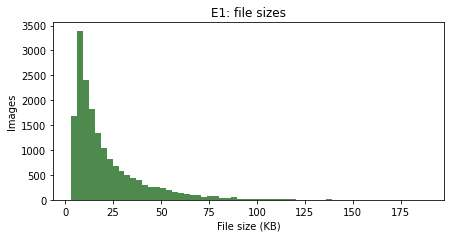

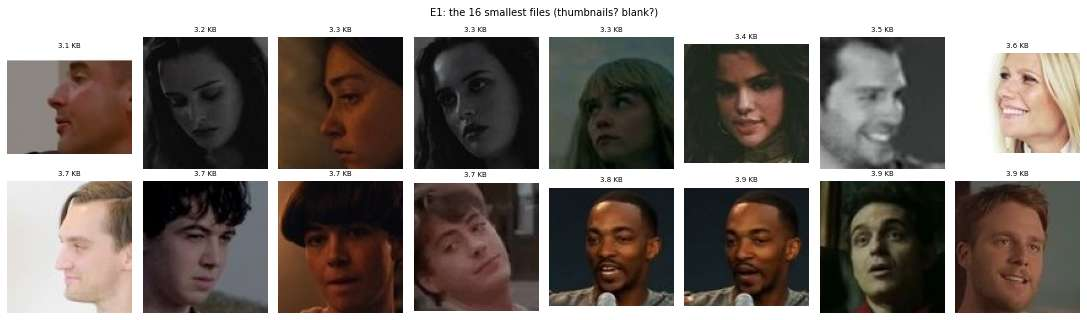

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(meta.loc[ok, "kb"], bins=60, color=GREEN)
ax.set(xlabel="File size (KB)", ylabel="Images", title="E1: file sizes")
save_fig("E1_file_sizes"); plt.show()

smallest = meta[ok].nsmallest(16, "kb")
show_grid(smallest["path"], titles=[f"{k:.1f} KB" for k in smallest["kb"]],
          suptitle="E1: the 16 smallest files (thumbnails? blank?)", save="E1_smallest_files")

##### EDA 2 - (Images PER PERSON)
###### **Question:** how uneven are the folder sizes?
###### **Why it matters:** a classifier leans towards big classes (your Part 1 model guessed Poe when unsure).
###### This decides class weights (B2) and how people are dealt into groups in Phase 4.

In [10]:
counts = meta[ok].groupby("person").size().sort_values()
print(counts.describe().round(1).to_string())
print("\nImbalance ratio (largest / smallest):", round(counts.max() / counts.min(), 2))
print("Smallest folders:"); print(counts.head(5).to_string())
print("Largest folders:");  print(counts.tail(5).to_string())

smallest_n = counts.min()
print(f"\nSmallest folder ({smallest_n}) split 70/15/15 leaves about "
      f"{int(smallest_n * 0.15)} photos each for validation and test.")

count    105.0
mean     167.0
std       34.1
min       86.0
25%      141.0
50%      169.0
75%      192.0
max      237.0

Imbalance ratio (largest / smallest): 2.76
Smallest folders:
person
Lionel Messi          86
Mark Zuckerberg       95
Cristiano Ronaldo     98
Brian J. Smith       102
Morgan Freeman       105
Largest folders:
person
margot robbie         221
Alexandra Daddario    225
Katherine Langford    226
Robert Downey Jr      233
Leonardo DiCaprio     237

Smallest folder (86) split 70/15/15 leaves about 12 photos each for validation and test.


In [11]:
n_names = meta["person"].nunique()
n_clean = meta["person"].str.lower().str.strip().nunique()
print(f"{n_names} names | {n_clean} after ignoring case and spaces")

105 names | 105 after ignoring case and spaces


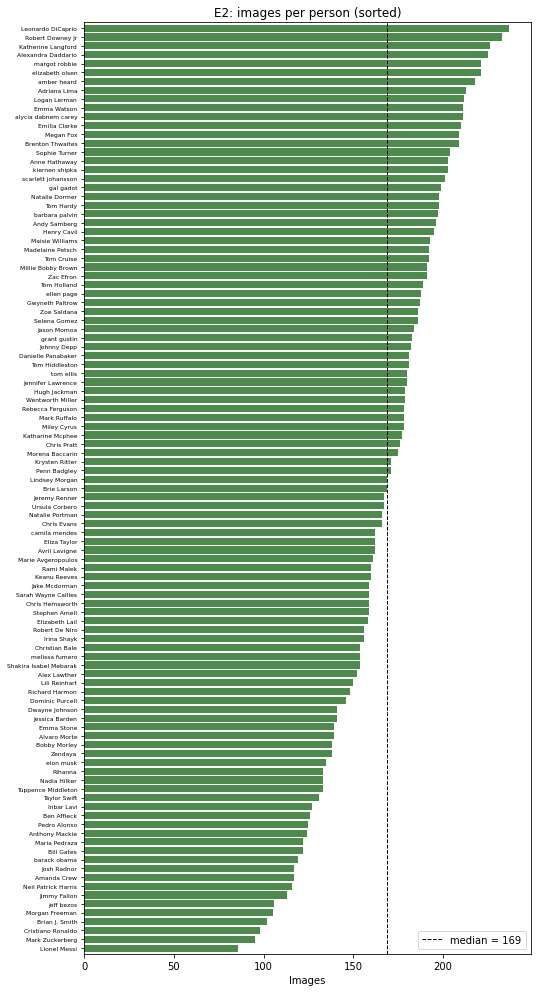

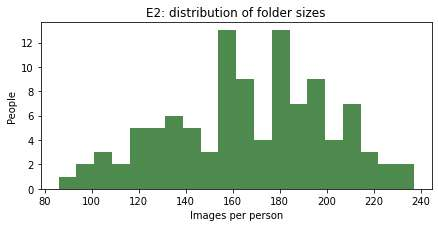

In [12]:
fig, ax = plt.subplots(figsize=(8, max(5, len(counts) * 0.16)))
counts.plot.barh(ax=ax, color=GREEN, width=0.8)
ax.axvline(counts.median(), ls="--", c="k", lw=1, label=f"median = {counts.median():.0f}")
ax.set(xlabel="Images", ylabel="", title="E2: images per person (sorted)")
ax.tick_params(axis="y", labelsize=6)
ax.legend(); save_fig("E2_images_per_person"); plt.show()

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(counts, bins=20, color=GREEN)
ax.set(xlabel="Images per person", ylabel="People", title="E2: distribution of folder sizes")
save_fig("E2_folder_size_hist"); plt.show()

##### EDA 3 - (Shapes and SIZES)
###### **Question:** what resolutions and aspect ratios are there?
###### **Why it matters:** decides the input size (proposal 128×128) and whether to stretch or pad (B4).
###### Anything smaller than the input size gets *upscaled*, which only adds blur.

In [13]:
meta["aspect"] = meta["w"] / meta["h"]
meta["min_side"] = meta[["w", "h"]].min(axis=1)
print(meta.loc[ok, ["w", "h", "aspect", "min_side", "kb"]].describe().round(2).to_string())

for size in (96, 112, 128, 160):
    share = (meta.loc[ok, "min_side"] < size).mean()
    print(f"Share of images with shortest side under {size} px: {share:.1%}")

              w         h    aspect  min_side        kb
count  17534.00  17534.00  17534.00  17534.00  17534.00
mean     211.46    225.72      0.94    210.94     21.66
std      101.51    112.82      0.04    101.06     19.70
min       80.00     82.00      0.57     80.00      3.14
25%      122.00    129.00      0.94    122.00      8.52
50%      175.00    185.00      0.94    175.00     14.42
75%      255.00    268.00      0.95    251.00     27.52
max      564.00    802.00      1.47    564.00    188.33
Share of images with shortest side under 96 px: 0.1%
Share of images with shortest side under 112 px: 15.0%
Share of images with shortest side under 128 px: 26.1%
Share of images with shortest side under 160 px: 39.4%


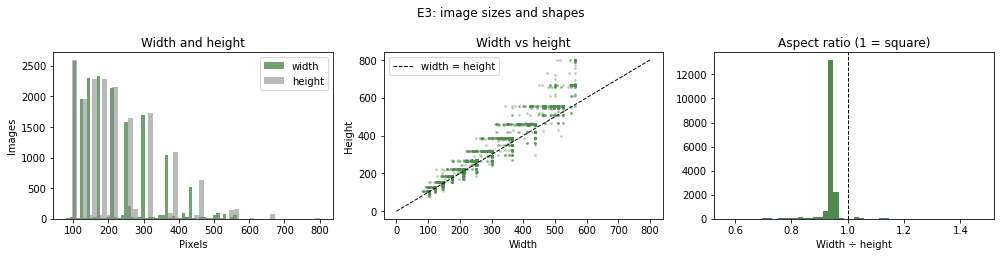

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(meta.loc[ok, "w"], bins=50, color=GREEN, alpha=0.8, label="width")
axes[0].hist(meta.loc[ok, "h"], bins=50, color=GREY, alpha=0.6, label="height")
axes[0].set(xlabel="Pixels", ylabel="Images", title="Width and height"); axes[0].legend()

axes[1].scatter(meta.loc[ok, "w"], meta.loc[ok, "h"], s=3, alpha=0.3, color=GREEN)
lim = [0, meta.loc[ok, ["w", "h"]].max().max()]
axes[1].plot(lim, lim, "k--", lw=1, label="width = height")
axes[1].set(xlabel="Width", ylabel="Height", title="Width vs height"); axes[1].legend()

axes[2].hist(meta.loc[ok, "aspect"], bins=50, color=GREEN)
axes[2].axvline(1, c="k", ls="--", lw=1)
axes[2].set(xlabel="Width ÷ height", title="Aspect ratio (1 = square)")
plt.suptitle("E3: image sizes and shapes"); plt.tight_layout()
save_fig("E3_sizes_shapes"); plt.show()

In [15]:
per_person_size = meta[ok].groupby("person")["min_side"].median().sort_values()
print("People whose photos are smallest (median shortest side, px):")
print(per_person_size.head(10).to_string())
print("\nIf one person's photos are all tiny, follow it up in E5 (shortcut check).")

People whose photos are smallest (median shortest side, px):
person
Amanda Crew            121.0
Anthony Mackie         121.0
Inbar Lavi             145.0
Neil Patrick Harris    145.0
Gwyneth Paltrow        145.0
Krysten Ritter         145.0
Pedro Alonso           146.0
Tom Holland            146.0
Mark Zuckerberg        146.0
Josh Radnor            146.0

If one person's photos are all tiny, follow it up in E5 (shortcut check).


##### EDA 4 - (Focus on the PIXELS)

<div style="font-size: 0.6em">

Four numbers per image describing **how it looks, not who is in it**. Every image is first resized to
128×128 so the numbers are comparable (sharpness especially depends on size).

| Measure | How | A strange value means |
| --- | --- | --- |
| Brightness | mean of the greyscale pixels (0–255) | near 0 almost black, near 255 blown out |
| Contrast | standard deviation of the greyscale pixels | very low = flat, washed out |
| Sharpness | variance of the Laplacian (an edge detector) | very low = blurry |
| Colourfulness | average gap between R, G and B | near 0 = a black-and-white photo saved as RGB |

</div>

In [16]:
def pixel_stats(path, size=128):
    img = cv2.imread(path)         
    if img is None:
        return {"brightness": np.nan, "contrast": np.nan, "sharpness": np.nan, "colourfulness": np.nan} 
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    b, g, r = cv2.split(img.astype(np.float32))
    return {
        "brightness": float(gray.mean()),
        "contrast": float(gray.std()),
        "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var()), # Laplacian lights up edges: many strong edges = sharp, few = blurry
        "colourfulness": float((np.abs(r - g).mean() + np.abs(g - b).mean()) / 2), # gap between colour channels: about 0 = a grey photo
    }


stats = pd.DataFrame([pixel_stats(p) for p in tqdm(meta.loc[ok, "path"], desc="E4 pixel stats")],
                     index=meta.index[ok])
meta = meta.drop(columns=stats.columns, errors="ignore").join(stats)
meta["log_sharpness"] = np.log1p(meta["sharpness"]) # sharpness has a few huge values; log makes the histogram readable
print(meta.loc[ok, ["brightness", "contrast", "sharpness", "colourfulness"]].describe().round(1).to_string())

E4 pixel stats:   0%|          | 0/17534 [00:00<?, ?it/s]

       brightness  contrast  sharpness  colourfulness
count     17534.0   17534.0    17534.0        17534.0
mean        112.9      59.9      734.5           21.6
std          30.6      12.8      565.9           10.6
min          14.0      14.8        9.9            0.0
25%          91.6      51.4      371.0           15.9
50%         112.0      60.0      598.8           21.6
75%         133.9      68.7      933.4           27.8
max         221.8     106.5    10699.4           81.6


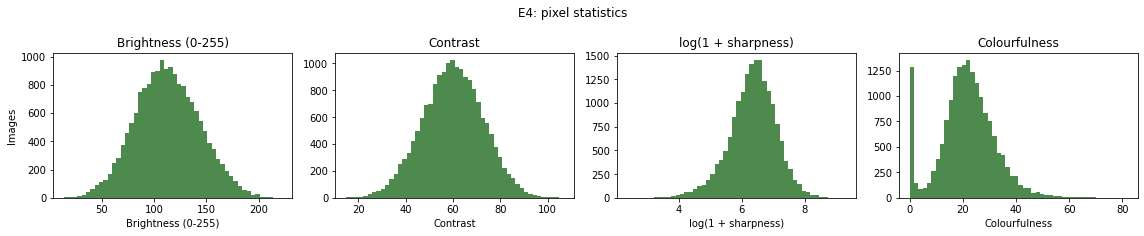

very dark (brightness < 40)                 97 images
very bright (brightness > 215)               2 images
very flat (contrast < 20)                   18 images
black-and-white (colourfulness < 2)       1316 images

These cut-offs are only for *looking* (E7). Keep black-and-white photos: night-mode security cameras are greyscale too.


In [17]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.3))
for ax, col, label in zip(axes,
                          ["brightness", "contrast", "log_sharpness", "colourfulness"],
                          ["Brightness (0-255)", "Contrast", "log(1 + sharpness)", "Colourfulness"]):
    ax.hist(meta.loc[ok, col].dropna(), bins=50, color=GREEN)
    ax.set(xlabel=label, title=label)
axes[0].set_ylabel("Images")
plt.suptitle("E4: pixel statistics"); plt.tight_layout()
save_fig("E4_pixel_stats"); plt.show()

flags_e4 = {
    "very dark (brightness < 40)": (meta["brightness"] < 40),
    "very bright (brightness > 215)": (meta["brightness"] > 215),
    "very flat (contrast < 20)": (meta["contrast"] < 20),
    "black-and-white (colourfulness < 2)": (meta["colourfulness"] < 2),
}
for name, mask in flags_e4.items():
    print(f"{name:40s} {int((ok & mask).sum()):5d} images")
print("\nThese cut-offs are only for *looking* (E7). Keep black-and-white photos: "
      "night-mode security cameras are greyscale too.")

##### EDA 5 - (`Shortcut` check)
###### **Question:** can anything *other than the face* give a person away — all their photos from one dark event,
###### all tiny, all black-and-white? In Part 1 the shortcut was character names; here it would be lighting or image quality.

###### Two tests:
###### 1. **Per-person medians as z-scores:** who is most unusual on each measure?
###### 2. **The Part 2 test:** a logistic regression that sees *only* the six photo-property numbers tries to guess the person.
######   Chance is 1 in 105. If it does much better, photo properties carry identity, and the CNN could cheat with them.

In [18]:
feats = ["brightness", "contrast", "log_sharpness", "colourfulness", "w", "h"]
d = meta.loc[ok, ["person"] + feats].dropna()

person_med = d.groupby("person")[feats].median()
z = (person_med - person_med.mean()) / person_med.std() # z-score: how unusual each person's typical photo is (0 = average person)
extreme = z.abs().max(axis=1).sort_values(ascending=False)
top10 = extreme.head(10)
print("The 10 most unusual people (largest |z| on any measure; |z| > 2.5 is worth a look):")
display(pd.concat([top10.rename("max |z|"), z.loc[top10.index]], axis=1).round(2))

The 10 most unusual people (largest |z| on any measure; |z| > 2.5 is worth a look):


,max |z|,brightness,contrast,log_sharpness,colourfulness,w,h
person,,,,,,,
Jessica Barden,4.48,-1.75,-3.14,-4.48,-0.11,-0.36,-0.34
Adriana Lima,4.05,-0.58,0.57,0.08,0.35,3.92,4.05
Shakira Isabel Mebarak,3.64,2.16,-2.74,1.38,3.64,-0.36,-0.34
Morgan Freeman,2.80,-0.84,-1.21,2.80,-1.10,2.21,1.56
Krysten Ritter,2.46,-1.76,2.36,-0.86,-2.46,-1.33,-1.28
Robert Downey Jr,2.33,0.11,1.29,2.33,-0.76,-0.36,-0.34
Emilia Clarke,2.30,0.58,0.36,0.46,-0.18,2.21,2.30
Natalie Portman,2.30,0.38,0.20,-0.52,0.50,2.21,2.30
amber heard,2.30,1.58,-0.85,1.19,1.22,2.21,2.30


In [19]:
bw_share = (meta.loc[ok, "colourfulness"] < 2).groupby(meta.loc[ok, "person"]).mean().sort_values(ascending=False)
print("People with the highest share of black-and-white photos:")
print(bw_share.head(10).round(3).to_string())
print(f"\nPeople with no black-and-white photos: {(bw_share == 0).sum()} of {len(bw_share)}")

People with the highest share of black-and-white photos:
person
Robert De Niro       0.276
Johnny Depp          0.242
Tom Hardy            0.202
Leonardo DiCaprio    0.186
Christian Bale       0.169
Keanu Reeves         0.169
barack obama         0.151
Logan Lerman         0.146
Alex Lawther         0.145
Ursula Corbero       0.138

People with no black-and-white photos: 2 of 105


In [20]:
min_count = d["person"].value_counts().min()
cv = StratifiedKFold(n_splits=min(5, min_count), shuffle=True, random_state=SEED)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

scores = cross_val_score(clf, d[feats], d["person"], cv=cv) # If photo properties ALONE (no face) can guess the person well above chance, the CNN could "cheat" by learning lighting or quality instead of faces

chance = 1 / d["person"].nunique()

print(f"Accuracy from photo properties alone: {scores.mean():.3f} (± {scores.std():.3f})")
print(f"Chance level:                         {chance:.3f}")
print(f"That's {scores.mean() / chance:.1f}× chance.")
print("Rough guide: under ~2× chance = little shortcut risk; well above = investigate the flagged people.")

Accuracy from photo properties alone: 0.045 (± 0.002)
Chance level:                         0.010
That's 4.7× chance.
Rough guide: under ~2× chance = little shortcut risk; well above = investigate the flagged people.


In [21]:
feats_cnn = ["brightness", "contrast", "log_sharpness", "colourfulness"] # what survives resizing to 128x128
scores_cnn = cross_val_score(clf, d[feats_cnn], d["person"], cv=cv)
print(f"Without width/height: {scores_cnn.mean():.3f} = {scores_cnn.mean() / chance:.1f}× chance")

Without width/height: 0.040 = 4.2× chance


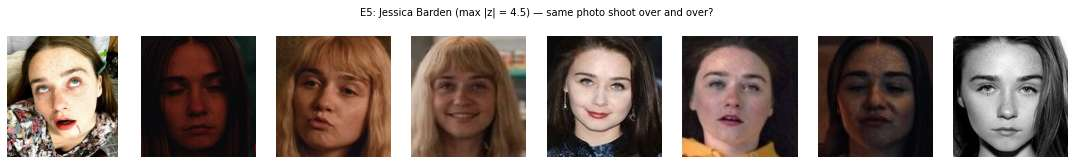

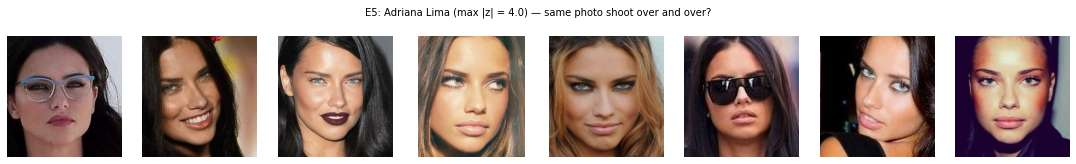

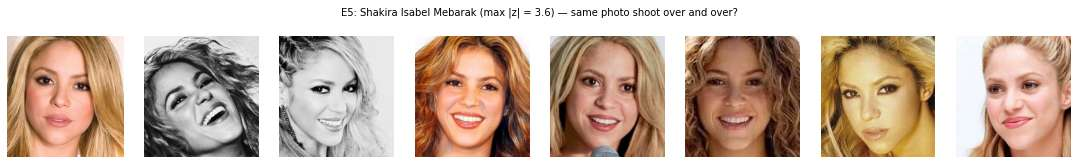

In [22]:
for person in top10.index[:3]:
    paths = meta[ok & (meta["person"] == person)].sample(
        n=min(8, int((ok & (meta["person"] == person)).sum())), random_state=SEED)["path"]
    show_grid(paths, suptitle=f"E5: {person} (max |z| = {top10[person]:.1f}) — same photo shoot over and over?")

##### EDA 6 - (DUPLICATES)

<div style="font-size: 0.6em">

**Question:** is the same photo repeated — within one person, or under two different people?
**Why it matters:** a photo in both training and test inflates the score (Part 2's duplicate-editions trap).

| Kind | Found with | Action (in B1) |
| --- | --- | --- |
| Exact copy, same person | identical MD5 of the file bytes | keep one |
| Near copy, same person (resized, recompressed) | perceptual-hash distance ≤ cut-off | keep one |
| Same photo under two people | near/exact match across folders | look: wrong label or two faces; usually drop both |

**pHash in one line:** it shrinks the image to a tiny greyscale grid and stores its broad light-and-dark pattern
as 64 bits. Similar-looking images differ in only a few bits (the *Hamming distance*, 0–64).

</div>

In [23]:
meta["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest()
               for p in tqdm(meta["path"], desc="E6 MD5")]
md5_groups = meta[ok].groupby("md5").agg(n=("path", "size"), people=("person", "nunique"))
exact = md5_groups[md5_groups["n"] > 1]
print("Groups of byte-identical files:", len(exact))
print("Extra copies (could be removed):", int((exact["n"] - 1).sum()))
print("Byte-identical files shared by different people:", int((exact["people"] > 1).sum()))

E6 MD5:   0%|          | 0/17534 [00:00<?, ?it/s]

Groups of byte-identical files: 1
Extra copies (could be removed): 1
Byte-identical files shared by different people: 0


In [24]:
def phash_int(path):
    with Image.open(path) as im:
        return int(str(imagehash.phash(im)), 16) # 64-bit hash as an integer


ok_idx = meta.index[ok].to_numpy()
hashes = np.array([phash_int(p) for p in tqdm(meta.loc[ok_idx, "path"], desc="E6 pHash")],
                  dtype=np.uint64)
meta.loc[ok_idx, "phash"] = [f"{h:016x}" for h in hashes]

# Hamming distance between every pair of images, in chunks so memory stays small
POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def hamming_block(a, b):
    x = np.bitwise_xor(a[:, None], b[None, :]) # XOR: a 1-bit wherever two hashes differ   
    # split each 64-bit result into 8 bytes, look up the 1-bits in each, add them up = how many bits differ (0-64)                 
    return POPCOUNT[x.view(np.uint8)].reshape(x.shape[0], x.shape[1], 8).sum(axis=2, dtype=np.uint8)

MAX_DIST = 10
persons = meta.loc[ok_idx, "person"].to_numpy()
parts, CHUNK = [], 500
for start in tqdm(range(0, len(hashes), CHUNK), desc="E6 comparing all pairs"):
    block = hamming_block(hashes[start:start + CHUNK], hashes)
    ii, jj = np.nonzero(block <= MAX_DIST)
    keep = jj > (ii + start) # each pair once, never an image with itself
    ii, jj = ii[keep], jj[keep]
    parts.append(pd.DataFrame({"i": ii + start, "j": jj, "dist": block[ii, jj]}))

near = pd.concat(parts, ignore_index=True)
near["a"] = ok_idx[near["i"]] # positions in the hash list -> row labels in meta
near["b"] = ok_idx[near["j"]]
near["same_person"] = persons[near["i"]] == persons[near["j"]]
print(f"Pairs within distance {MAX_DIST}: {len(near):,}")
display(near.groupby(["dist", "same_person"]).size().unstack(fill_value=0)
            .rename(columns={True: "same person", False: "different people"}))

E6 pHash:   0%|          | 0/17534 [00:00<?, ?it/s]

E6 comparing all pairs:   0%|          | 0/36 [00:00<?, ?it/s]

Pairs within distance 10: 13,673


same_person,different people,same person
dist,,
0,0,48
2,1,36
4,13,56
6,172,122
8,1610,228
10,10742,645


###### **Choose the cut-off by looking.** Below are example pairs at each distance. Set `DUP_CUTOFF` to the largest distance where pairs are still *the same photo* — not merely *the same person in a different photo*. Different photos of the same person are exactly what you want to keep.

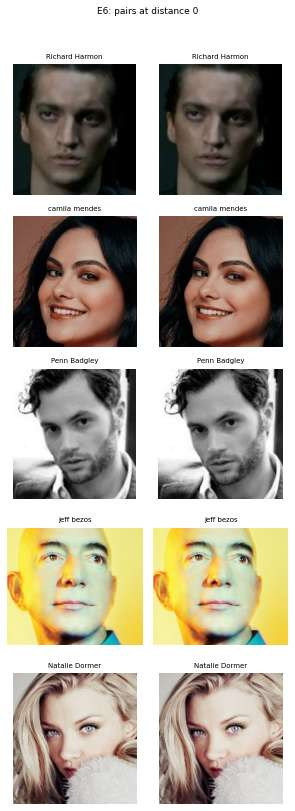

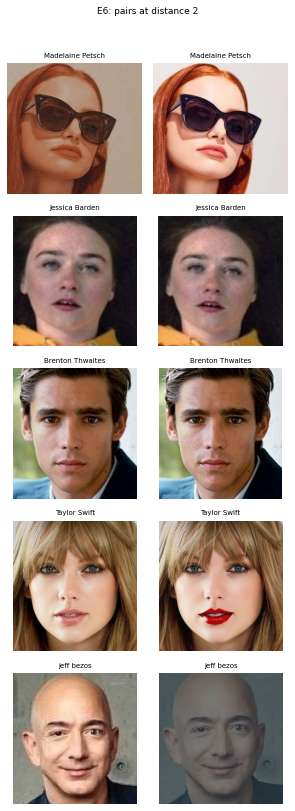

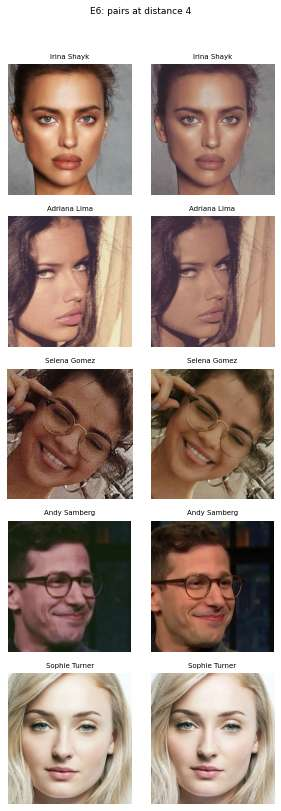

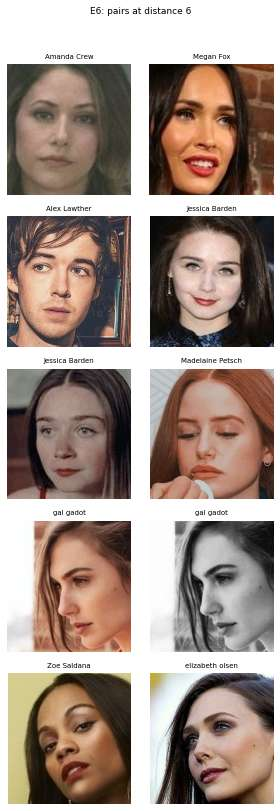

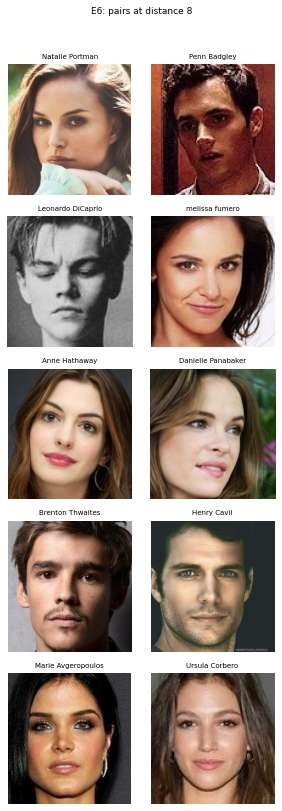

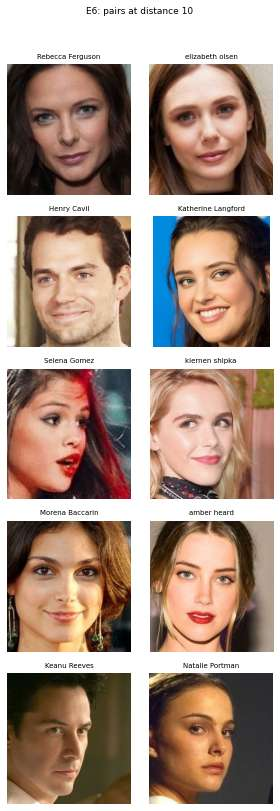

In [25]:
def show_pairs(df, title, n=5):
    if df.empty:
        print("No pairs:", title)
        return
    df = df.sample(n=min(n, len(df)), random_state=SEED)
    fig, axes = plt.subplots(len(df), 2, figsize=(4.2, 2.2 * len(df)))
    axes = np.atleast_2d(axes)
    for row, (_, r) in zip(axes, df.iterrows()):
        for ax, idx in zip(row, (r["a"], r["b"])):
            ax.imshow(cv2.cvtColor(cv2.imread(meta.at[idx, "path"]), cv2.COLOR_BGR2RGB))
            ax.set_title(meta.at[idx, "person"], fontsize=7); ax.axis("off")
    fig.suptitle(title, fontsize=9, y=1.02); plt.tight_layout(); plt.show()


for dist in (0, 2, 4, 6, 8, 10):
    show_pairs(near[near["dist"] == dist], f"E6: pairs at distance {dist}")

Cross-person pairs at distance 4 or less: 14


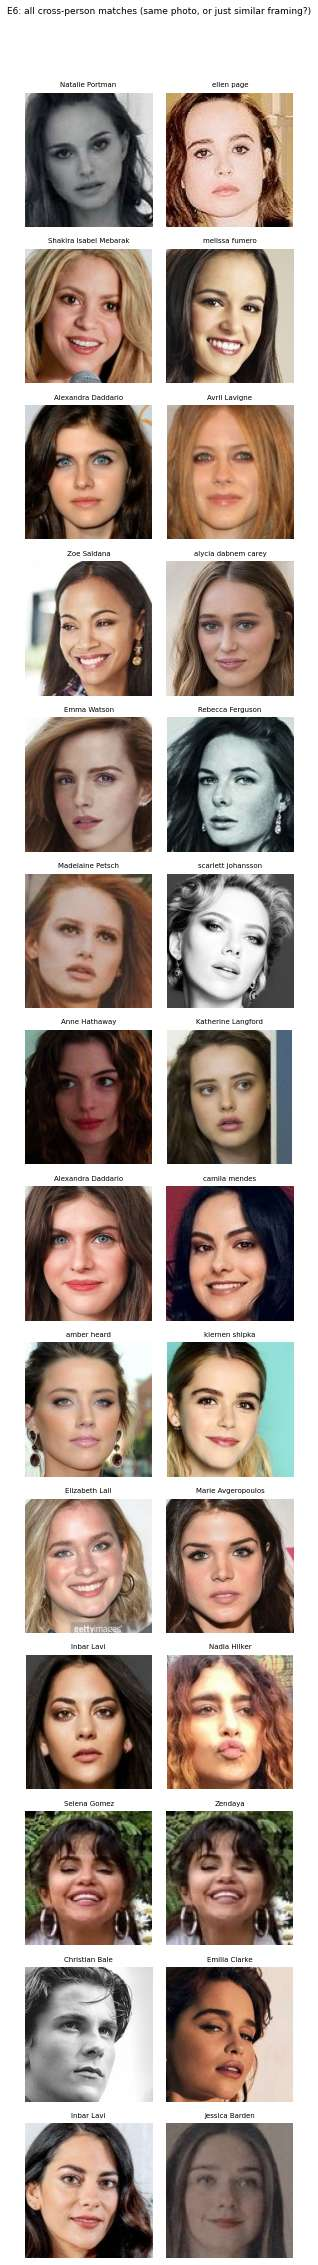

In [26]:
cross_check = near[(near["dist"] <= 4) & ~near["same_person"]]
print("Cross-person pairs at distance 4 or less:", len(cross_check))
show_pairs(cross_check, "E6: all cross-person matches (same photo, or just similar framing?)", n=len(cross_check))

In [27]:
names = cross_check.assign(person_a=meta.loc[cross_check["a"], "person"].values,
                           person_b=meta.loc[cross_check["b"], "person"].values)
display(names[["dist", "person_a", "person_b"]])

,dist,person_a,person_b
927,4,Alexandra Daddario,Avril Lavigne
1143,4,Alexandra Daddario,camila mendes
2411,4,Anne Hathaway,Katherine Langford
3682,4,Christian Bale,Emilia Clarke
4457,4,Elizabeth Lail,Marie Avgeropoulos
4975,4,Emma Watson,Rebecca Ferguson
5675,4,Inbar Lavi,Jessica Barden
5870,4,Inbar Lavi,Nadia Hilker
9531,4,Madelaine Petsch,scarlett johansson
11441,4,Natalie Portman,ellen page


,images flagged,people affected
"extra copies, same person",136,61
same photo under two people,2,2


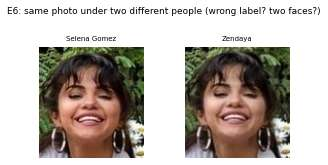

In [28]:
DUP_CUTOFF = 4  # <- set this after looking at the pairs above

dups = near[near["dist"] <= DUP_CUTOFF]
same = dups[dups["same_person"]]

CROSS_CUTOFF = 0 # different people: pHash at 2-4 was mostly similar framing (false alarms)
CONFIRMED_CROSS = [12283] # near-row label of the Selena Gomez / Zendaya pair (same photo, checked by eye)
cross = near[((near["dist"] <= CROSS_CUTOFF) | near.index.isin(CONFIRMED_CROSS)) & ~near["same_person"]]

# Group same-person duplicates (A~B and B~C -> one group) and keep the first image of each group
parent = {}
def find(x):
    parent.setdefault(x, x) # a new image starts as its own root
    while parent[x] != x:
        parent[x] = parent[parent[x]] # shortcut the chain so later look-ups are faster
        x = parent[x]
    return x

for a, b in zip(same["a"], same["b"]):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[max(ra, rb)] = min(ra, rb) # join two groups: the lowest row number becomes the root (the copy we keep)

drop_dupes = [i for i in parent if find(i) != i] # every image that isn't its group's root is an extra copy

meta["flag_duplicate"] = meta.index.isin(drop_dupes)
meta["flag_cross_person_dup"] = meta.index.isin(set(cross["a"]) | set(cross["b"]))

summary_e6 = pd.DataFrame({
    "images flagged": [int(meta["flag_duplicate"].sum()), int(meta["flag_cross_person_dup"].sum())],
    "people affected": [meta.loc[meta["flag_duplicate"], "person"].nunique(),
                        meta.loc[meta["flag_cross_person_dup"], "person"].nunique()],
}, index=["extra copies, same person", "same photo under two people"])
display(summary_e6)
show_pairs(cross, "E6: same photo under two different people (wrong label? two faces?)", n=10)

##### EDA 7 - (LOOK at the photos)
###### Numbers miss what eyes catch. Four kinds of picture:

###### 1. **Random grid** across the whole set, and 8 photos each for 4 random people.
###### 2. **Extremes gallery:** the tails of every E3/E4 histogram, made visible.
###### 3. **Average face** of 2,000 random photos: sharp = faces sit in the same place in every crop; a blurry ghost = position and size vary (consider re-cropping in B3).
###### 4. **Variation map:** where photos differ most. Ideally background and hair, not the eyes.

###### Write down: crop tightness, pose range (straight on / three-quarter / profile), glasses and hats, watermarks or text, age range, expressions.

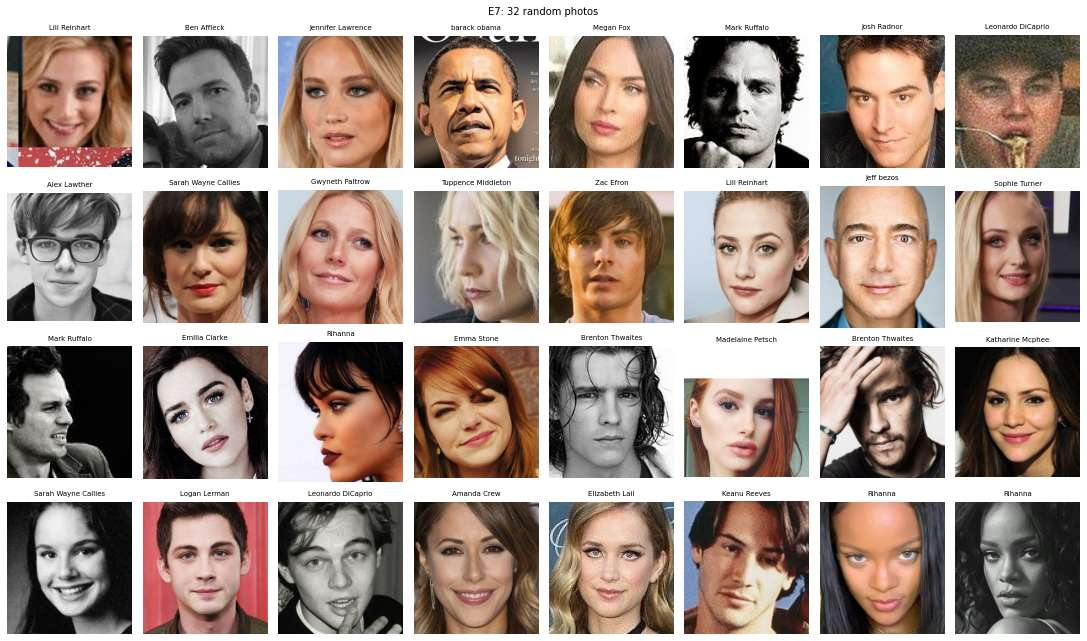

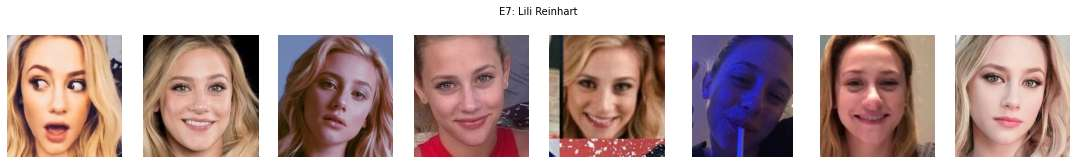

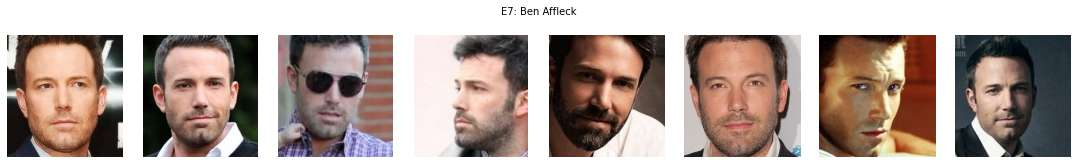

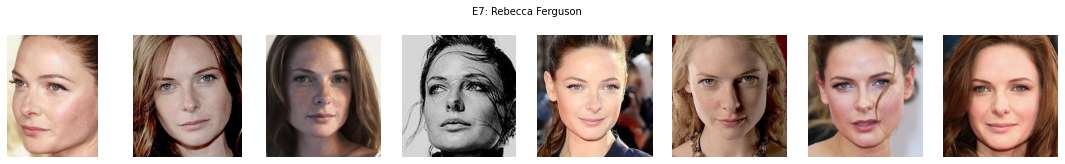

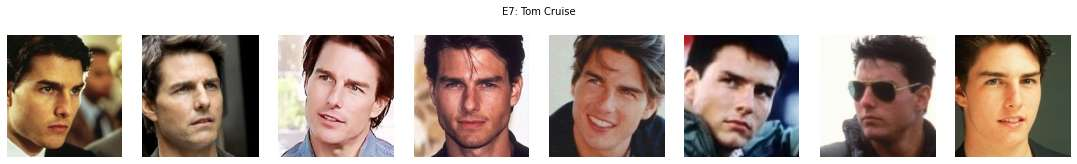

In [29]:
rand = meta[ok].sample(n=min(32, int(ok.sum())), random_state=SEED)
show_grid(rand["path"], titles=list(rand["person"]), suptitle="E7: 32 random photos", save="E7_random_grid")

rng = np.random.default_rng(SEED)
for person in rng.choice(sorted(meta.loc[ok, "person"].unique()), size=4, replace=False):
    sub = meta[ok & (meta["person"] == person)]
    show_grid(sub.sample(n=min(8, len(sub)), random_state=SEED)["path"], suptitle=f"E7: {person}")

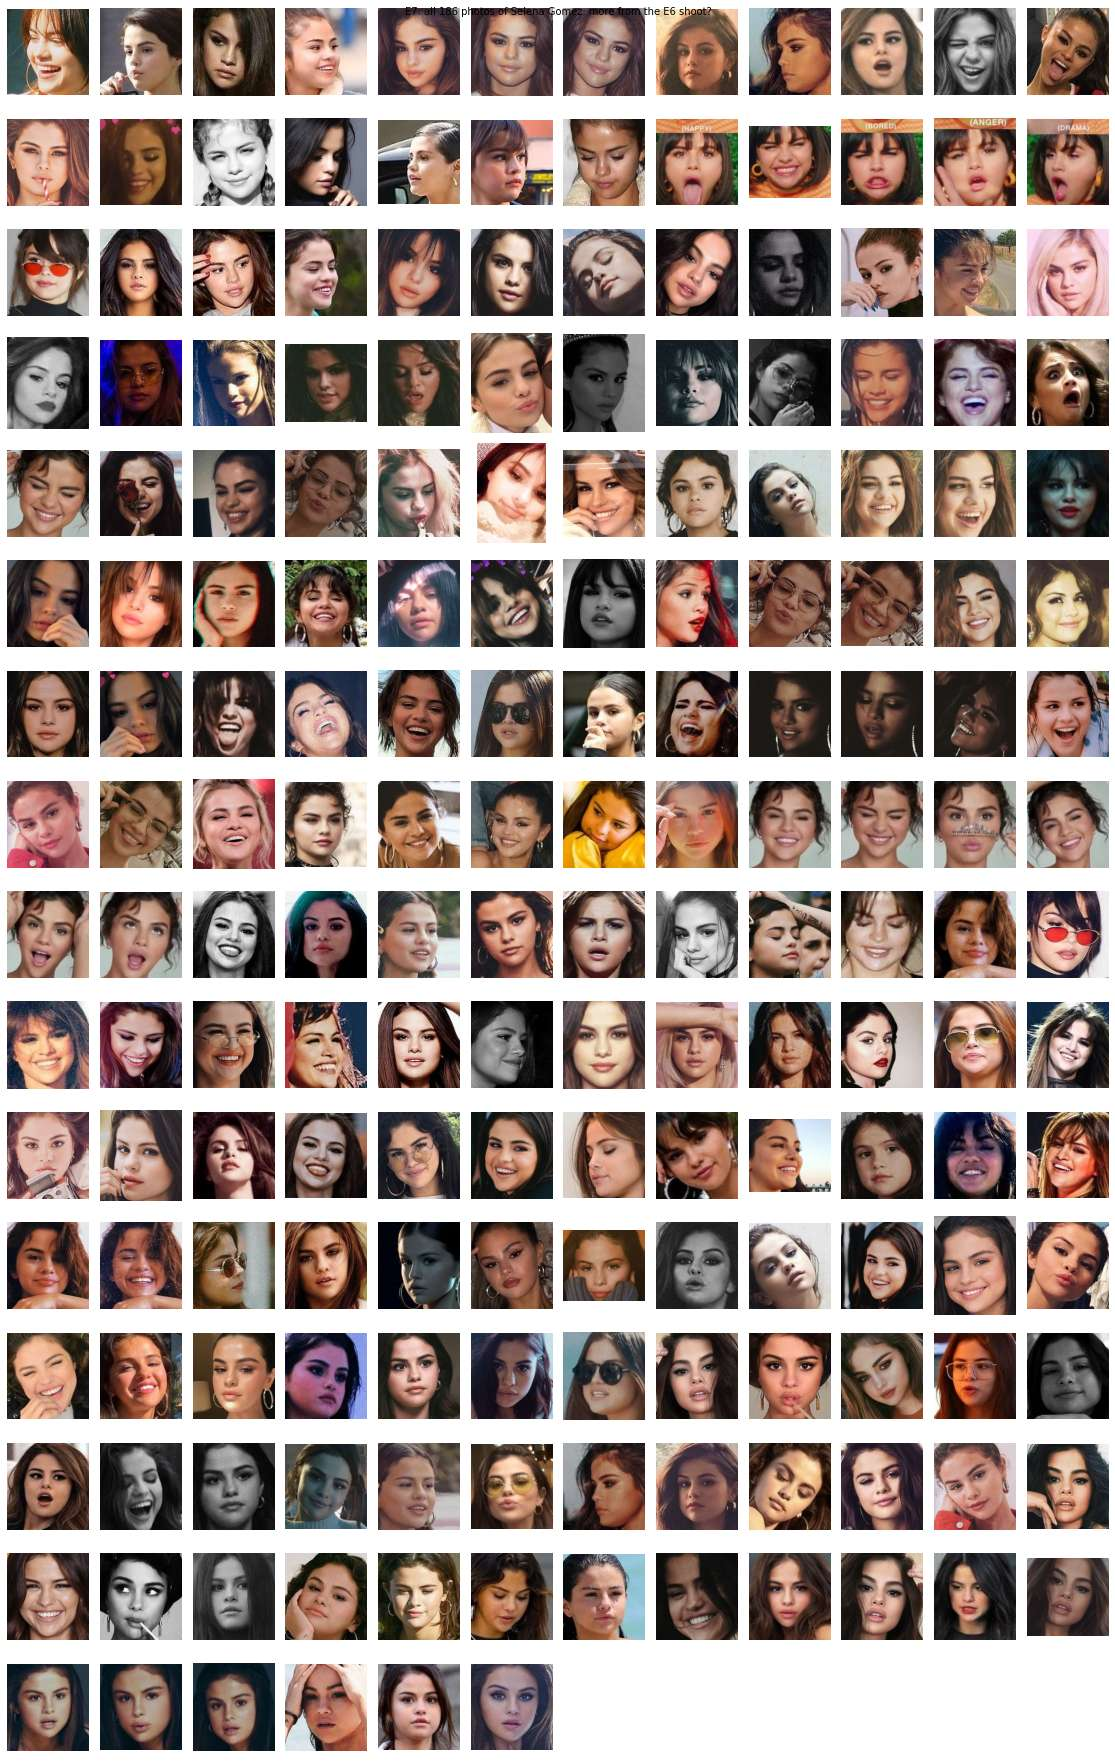

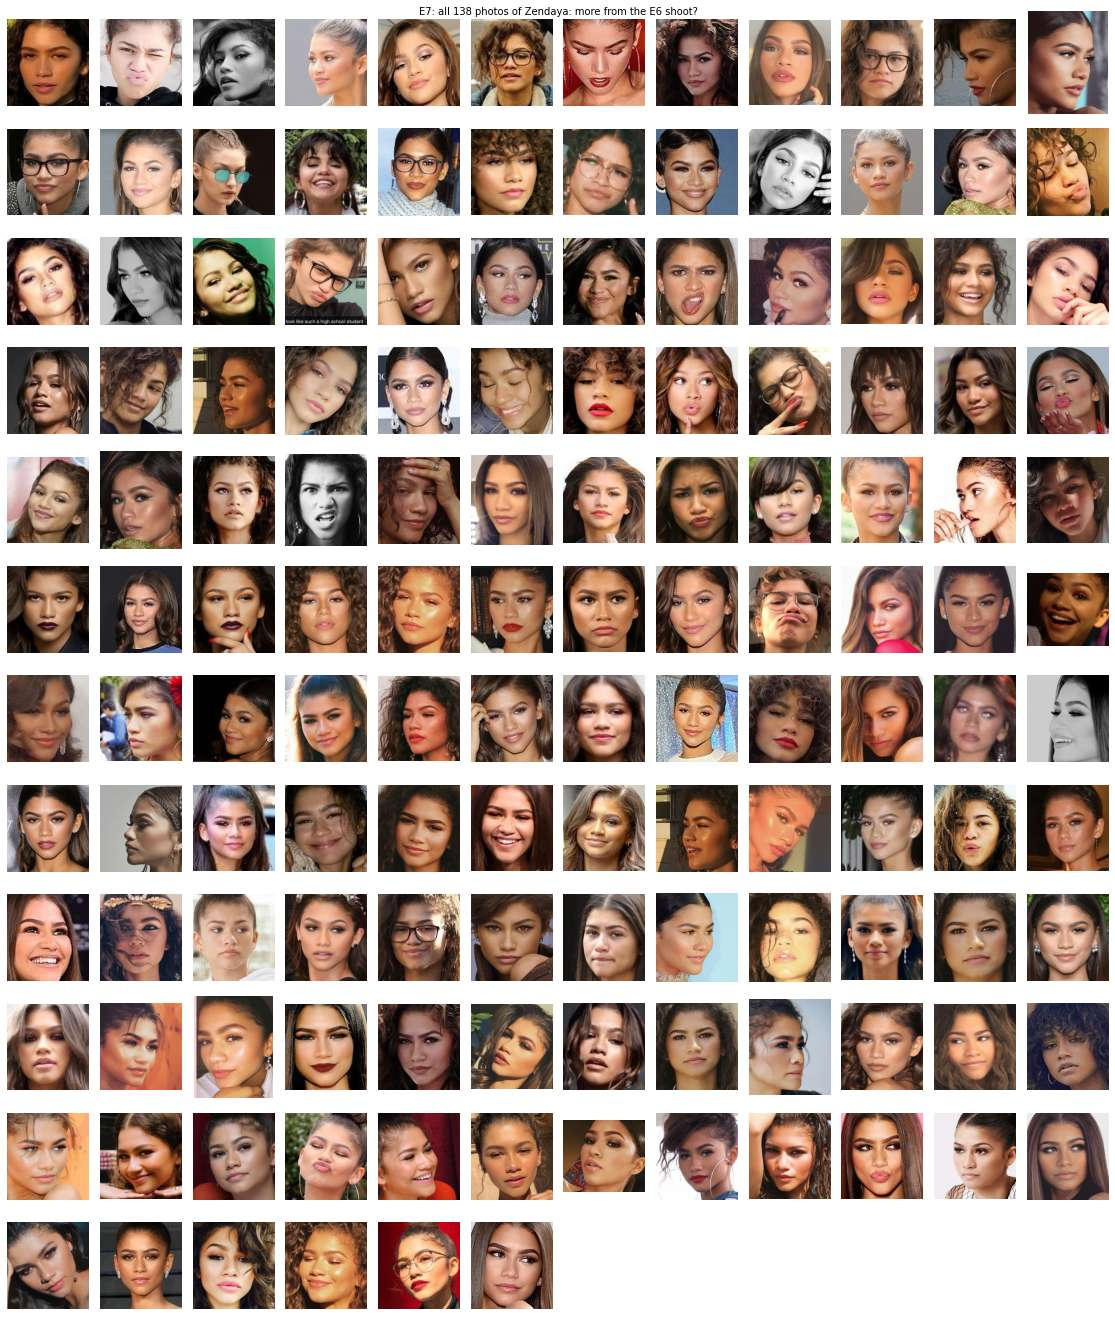

In [30]:
for person in ("Selena Gomez", "Zendaya"):
    sub = meta[ok & (meta["person"] == person)]
    show_grid(sub["path"], ncols=12, size=1.3, suptitle=f"E7: all {len(sub)} photos of {person}: more from the E6 shoot?")

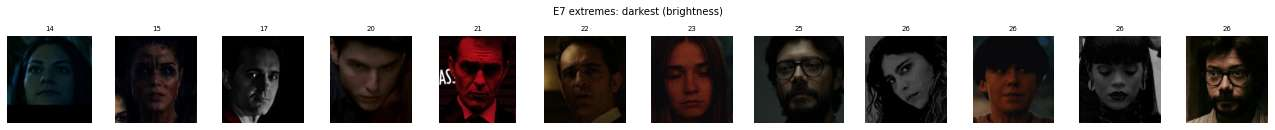

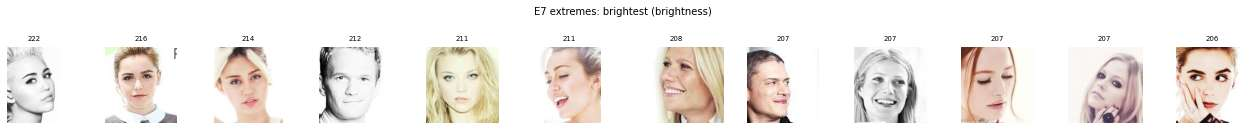

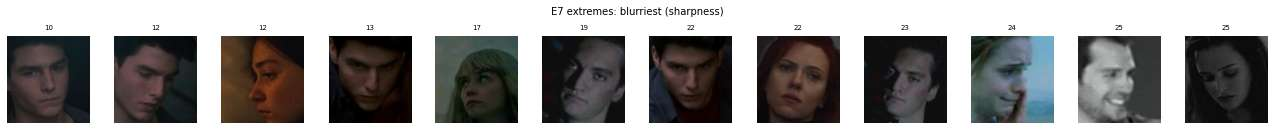

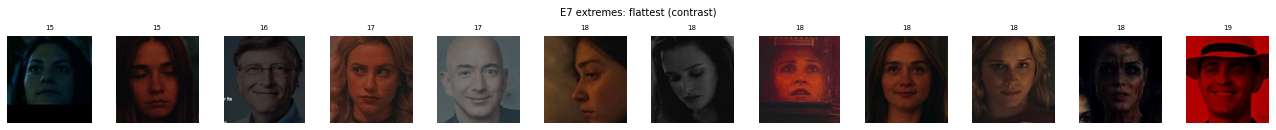

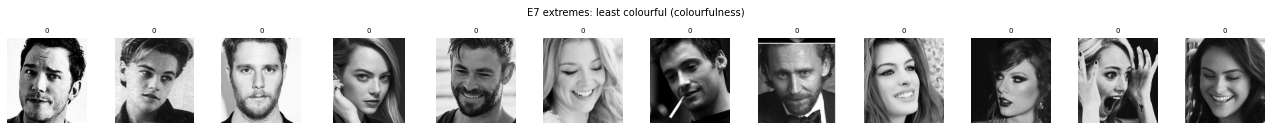

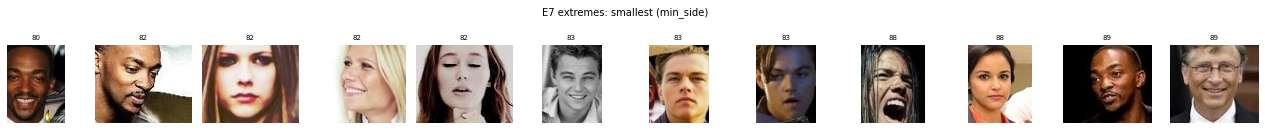

In [31]:
extremes = {
    "darkest": meta[ok].nsmallest(12, "brightness"),
    "brightest": meta[ok].nlargest(12, "brightness"),
    "blurriest": meta[ok].nsmallest(12, "sharpness"),
    "flattest": meta[ok].nsmallest(12, "contrast"),
    "least colourful": meta[ok & (meta["colourfulness"] < 2)].sample(12, random_state=SEED),
    "smallest": meta[ok].nsmallest(12, "min_side"),
}
value_col = {"darkest": "brightness", "brightest": "brightness", "blurriest": "sharpness",
             "flattest": "contrast", "least colourful": "colourfulness", "smallest": "min_side"}
for name, df in extremes.items():
    col = value_col[name]
    show_grid(df["path"], titles=[f"{v:.0f}" for v in df[col]], ncols=12, size=1.5,
              suptitle=f"E7 extremes: {name} ({col})", save=f"E7_extremes_{name.replace(' ', '_')}")

E7 average face:   0%|          | 0/2000 [00:00<?, ?it/s]

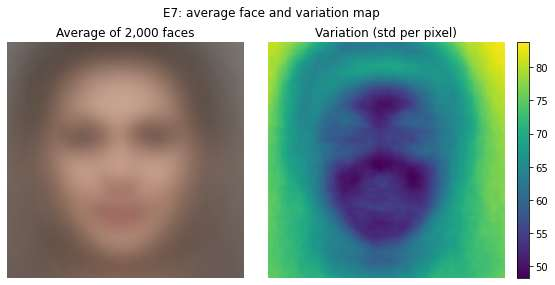

In [32]:
def load_small_rgb(path, size=128):
    img = cv2.imread(path)
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA).astype(np.float32)

sample_paths = meta[ok].sample(n=min(2000, int(ok.sum())), random_state=SEED)["path"]
stack = np.stack([im for im in (load_small_rgb(p) for p in tqdm(sample_paths, desc="E7 average face"))
                  if im is not None])
mean_face = stack.mean(axis=0).astype(np.uint8)
variation = stack.std(axis=0).mean(axis=2) # how much each pixel changes across the 2,000 faces (averaged over R, G, B)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(mean_face); axes[0].set_title(f"Average of {len(stack):,} faces")
im = axes[1].imshow(variation, cmap="viridis"); axes[1].set_title("Variation (std per pixel)")
plt.colorbar(im, ax=axes[1], fraction=0.046)
for ax in axes: ax.axis("off")
plt.suptitle("E7: average face and variation map"); plt.tight_layout()
save_fig("E7_average_face"); plt.show()

##### EDA 8 - (more than 1 face checks)
<div style="font-size: 0.6em">

A simple OpenCV face detector (Haar cascade) counts faces in every image and measures how much of the
image the biggest face fills. It only finds faces **looking at the camera**, so "0 faces" often just means
a side profile — always look before dropping anything.

| Result | Usually means | Action |
| --- | --- | --- |
| 1 face | normal | keep |
| 0 faces | side profile, covered face, or not a face | look; drop non-faces only |
| 2+ faces | two people, or a false detection | look; drop if really two people |
| very small face share | loose crop, lots of background | candidate for re-cropping (B3) |

Images are shrunk to at most 256 px first (much faster) and given a 20 px border (tight crops need a margin to be detected).
This cell takes a few minutes for ~17,500 images.

</div>

In [33]:
CASCADE = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
assert not CASCADE.empty(), "Face detector failed to load"

def face_info(path, max_side=256, border=20):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return {"n_faces": np.nan, "face_frac": np.nan}
    scale = max_side / max(img.shape)
    if scale < 1: # shrink big photos so detection is fast
        img = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    img = cv2.copyMakeBorder(img, border, border, border, border, cv2.BORDER_REPLICATE) # add a 20 px border: tight crops cut off the face edge, and the detector needs some margin
    
    faces = CASCADE.detectMultiScale(img, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))# scaleFactor 1.1 = search at many face sizes; minNeighbors 5 = needs several overlapping hits (fewer false alarms)

    biggest = max((int(w) * int(h) for (x, y, w, h) in faces), default=0)
    return {"n_faces": len(faces), "face_frac": biggest / img.size}

faces = pd.DataFrame([face_info(p) for p in tqdm(meta.loc[ok, "path"], desc="E8 face detection")],
                     index=meta.index[ok])
meta = meta.drop(columns=faces.columns, errors="ignore").join(faces)

face_bucket = meta.loc[ok, "n_faces"].clip(upper=2).map({0: "0 faces", 1: "1 face", 2: "2+ faces"})
print(face_bucket.value_counts().to_string())

E8 face detection:   0%|          | 0/17534 [00:00<?, ?it/s]

n_faces
1 face      15646
0 faces      1784
2+ faces      104


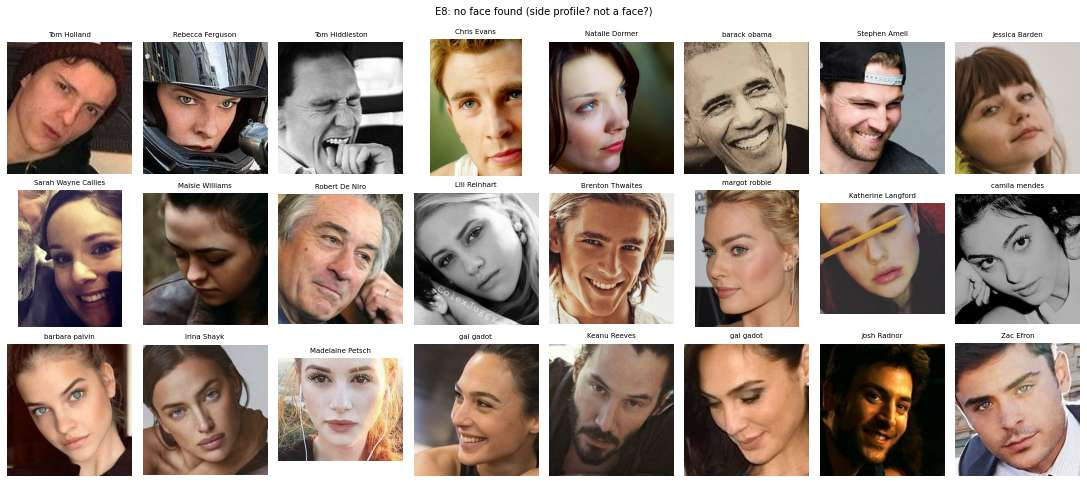

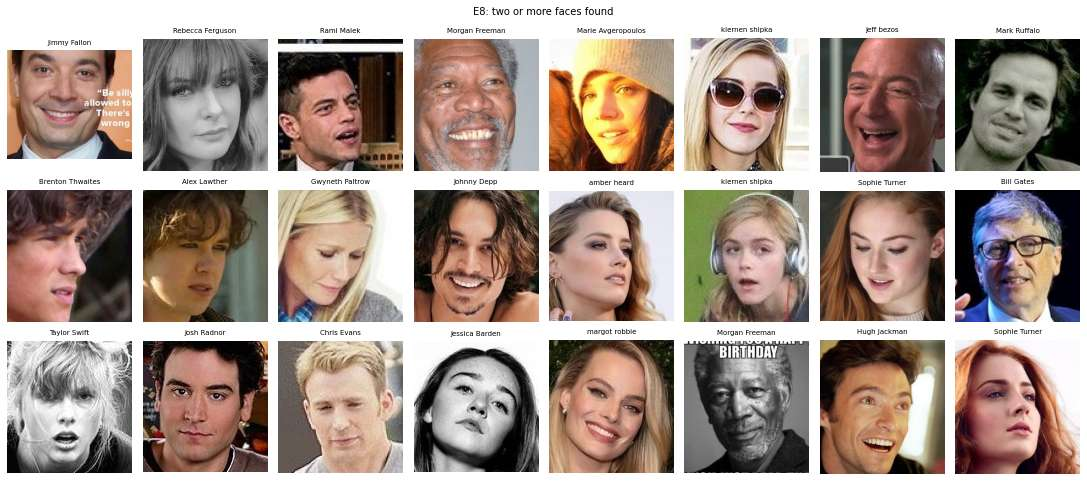

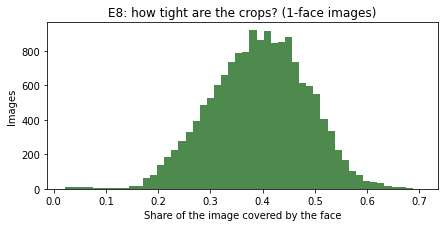

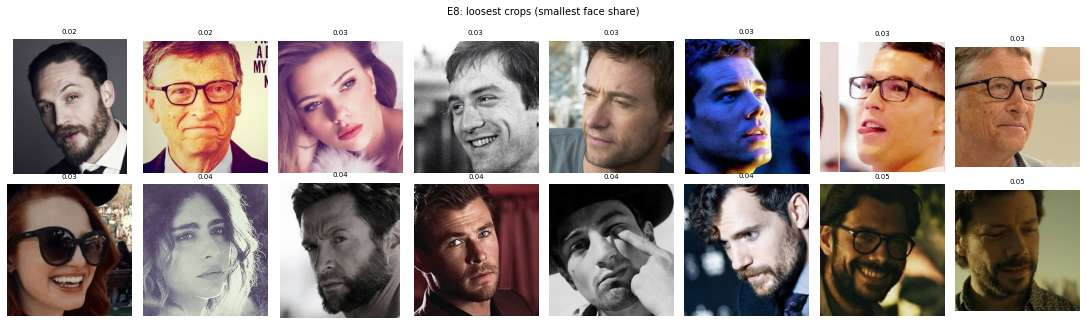

In [34]:
zero = meta[ok & (meta["n_faces"] == 0)]
multi = meta[ok & (meta["n_faces"] >= 2)]
zero_pick = zero.sample(n=min(24, len(zero)), random_state=SEED)
show_grid(zero_pick["path"], titles=list(zero_pick["person"]),
          suptitle="E8: no face found (side profile? not a face?)", save="E8_zero_faces")
          
multi_pick = multi.sample(n=min(24, len(multi)), random_state=SEED)
show_grid(multi_pick["path"], titles=list(multi_pick["person"]),
          suptitle="E8: two or more faces found", save="E8_multi_faces")

one = meta[ok & (meta["n_faces"] == 1)]
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(one["face_frac"], bins=50, color=GREEN)
ax.set(xlabel="Share of the image covered by the face", ylabel="Images",
       title="E8: how tight are the crops? (1-face images)")
save_fig("E8_face_share"); plt.show()

loose = one.nsmallest(16, "face_frac")
show_grid(loose["path"], titles=[f"{v:.2f}" for v in loose["face_frac"]],
          suptitle="E8: loosest crops (smallest face share)", save="E8_loose_crops")

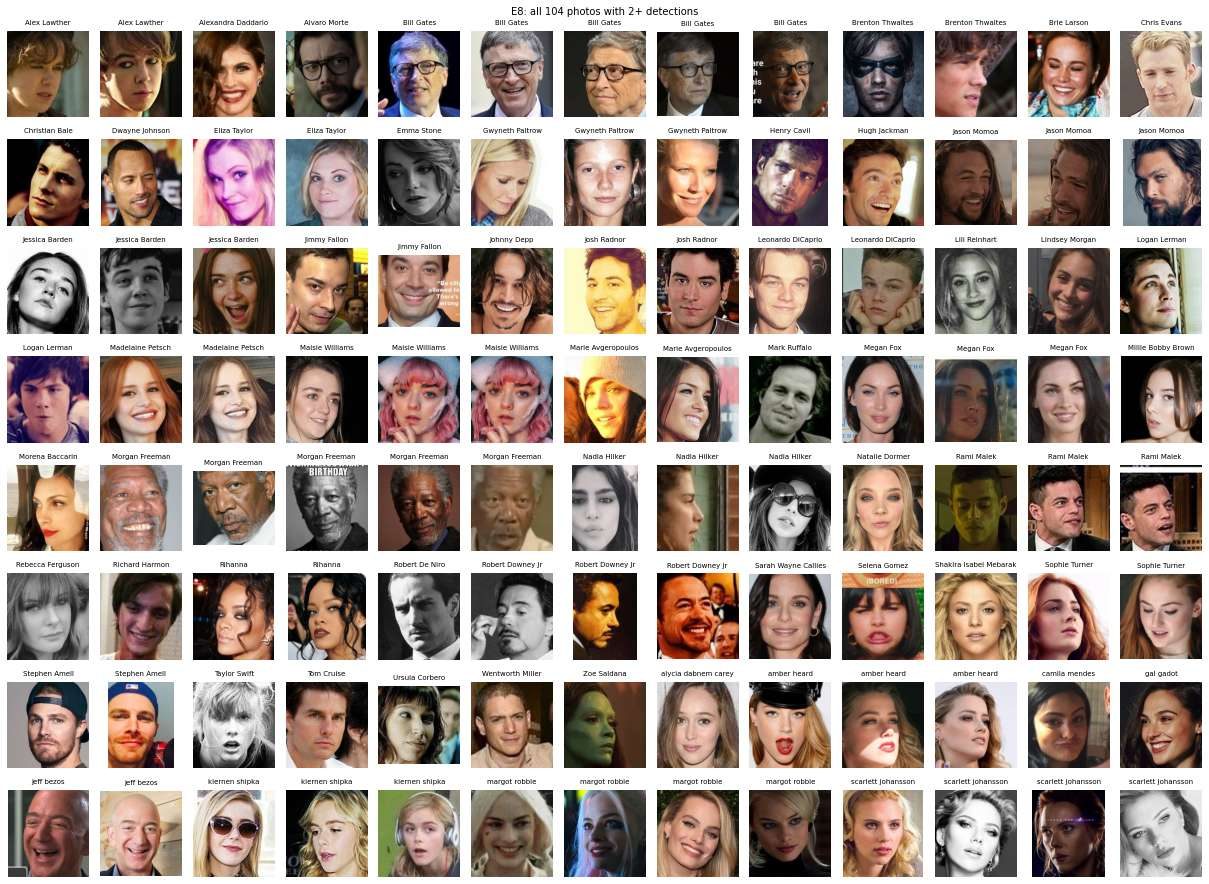

In [35]:
show_grid(multi["path"], titles=list(multi["person"]), ncols=13, size=1.3,
          suptitle=f"E8: all {len(multi)} photos with 2+ detections")

###### **Label spot check (manual).** Scraped data contains mistakes. Look through every person's grid (about 15 seconds each, under 30 minutes for all) and add any **wrong-person** photo to `SUSPECTS`. Each tile's title is its file name, so you can look up its path with the example line in the cell.

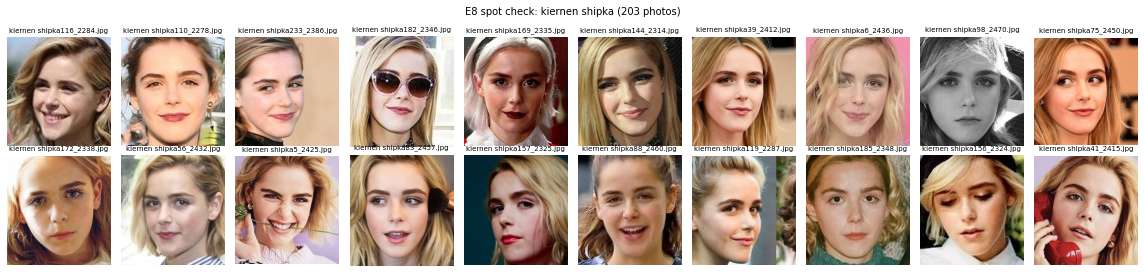

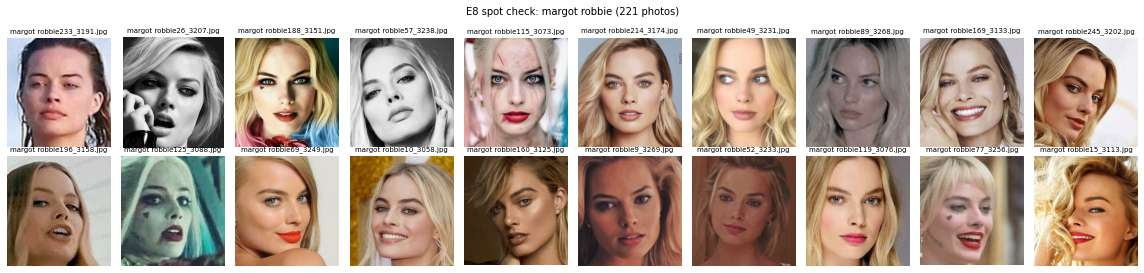

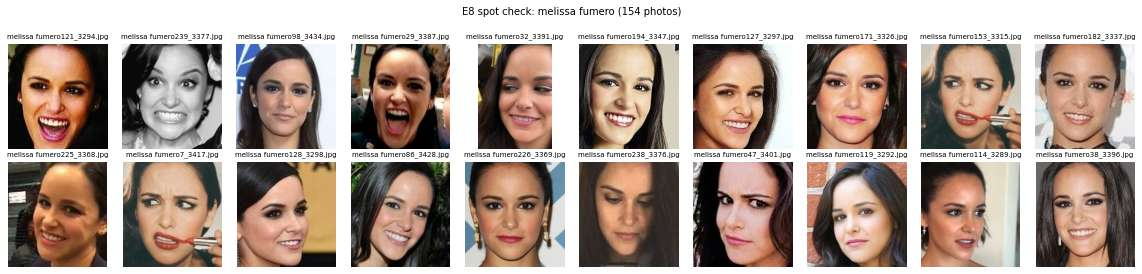

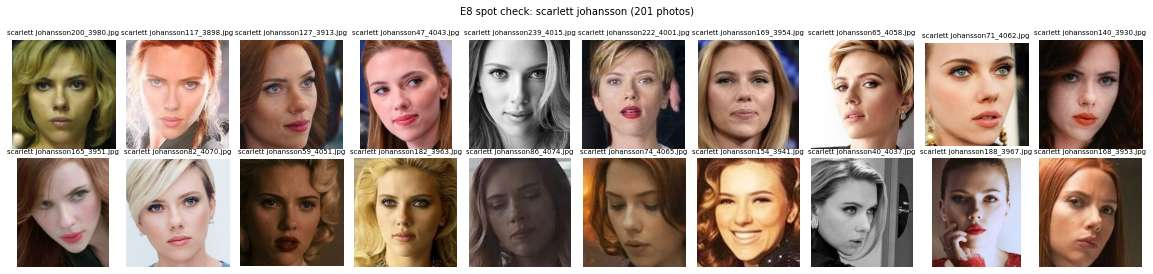

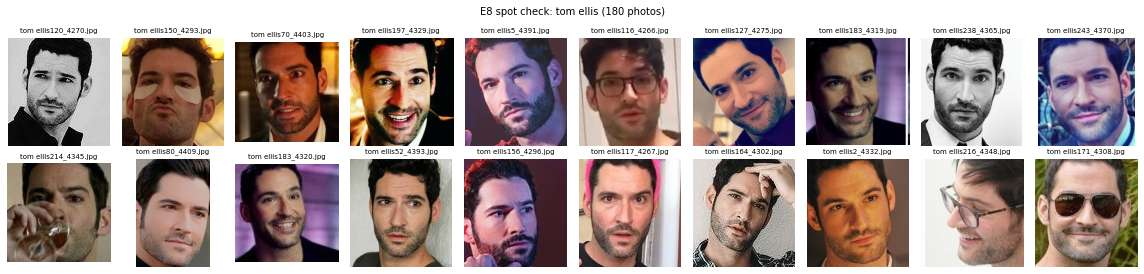

In [36]:
def spot_check(person, n=20):
    sub = meta[ok & (meta["person"] == person)]
    pick = sub.sample(n=min(n, len(sub)), random_state=SEED)
    show_grid(pick["path"], titles=list(pick["file"]), ncols=10, size=1.6,
              suptitle=f"E8 spot check: {person} ({len(sub)} photos)")

PEOPLE = sorted(meta.loc[ok, "person"].unique())
SUSPECTS = [] # e.g. SUSPECTS.append(meta.loc[(meta.person == "X") & (meta.file == "X12_3.jpg"), "path"].item())

BATCH = 10 # a very tedious task that had me looking up what celebrities look like.
for person in PEOPLE[BATCH * 10:(BATCH + 1) * 10]:
    spot_check(person)

In [37]:
meta["flag_wrong_person"] = meta["path"].isin(SUSPECTS)
print("Wrong-person photos logged:", int(meta["flag_wrong_person"].sum()))

Wrong-person photos logged: 0


##### EDA 9 - (actual SUBJECTS of dataset)
###### Describe the set **as a group** so the report can say honestly who the model was and wasn't built on:
###### what kind of people (actors, models, musicians…), what kind of photos (professional, red carpet, heavy make-up, era), and where they come from (scraped from Pinterest, no consent for face recognition).

###### **Don't hand-label anyone's race or ethnicity** — it would be guesswork from photos, the very practice the report criticises.
###### State the skew in words and recommend testing on the press's own consenting staff before launch.

In [38]:
names = sorted(meta["person"].unique(), key=str.lower)
print(f"{len(names)} people:\n")
for i in range(0, len(names), 4):
    print("  ".join(f"{n:<26}" for n in names[i:i + 4]))

print("\nWhole-set photo profile (medians):")
print(meta.loc[ok, ["w", "h", "brightness", "contrast", "colourfulness"]].median().round(1).to_string())
print("Share with exactly one detected frontal face:", f"{(meta.loc[ok, 'n_faces'] == 1).mean():.1%}")

105 people:

Adriana Lima                Alex Lawther                Alexandra Daddario          Alvaro Morte              
alycia dabnem carey         Amanda Crew                 amber heard                 Andy Samberg              
Anne Hathaway               Anthony Mackie              Avril Lavigne               barack obama              
barbara palvin              Ben Affleck                 Bill Gates                  Bobby Morley              
Brenton Thwaites            Brian J. Smith              Brie Larson                 camila mendes             
Chris Evans                 Chris Hemsworth             Chris Pratt                 Christian Bale            
Cristiano Ronaldo           Danielle Panabaker          Dominic Purcell             Dwayne Johnson            
Eliza Taylor                Elizabeth Lail              elizabeth olsen             ellen page                
elon musk                   Emilia Clarke               Emma Stone                  Emma Watson    

##### EDA 10 - (Raw pixel map)
###### Each photo of the **validation newcomers** becomes 4,096 raw greyscale numbers (64×64), squeezed to 2-D with PCA (to 50) and then t-SNE. Expect dots to group by **lighting or pose, not by person**: in raw pixels, two people in similar light look more alike than one person in different light. In Phase 9 you draw the same map from CNN fingerprints; if those cluster by person and these don't, that one figure shows what the CNN learned.

###### Until Phase 4 creates `splits.json`, this runs as a **preview** on 15 random people. Re-run it after Phase 4. `splits.json` is expected to hold `{"people": {"<name>": "staff" | "val_newcomer" | "test_newcomer"}, ...}`.


E10 raw pixels:   0%|          | 0/2493 [00:00<?, ?it/s]

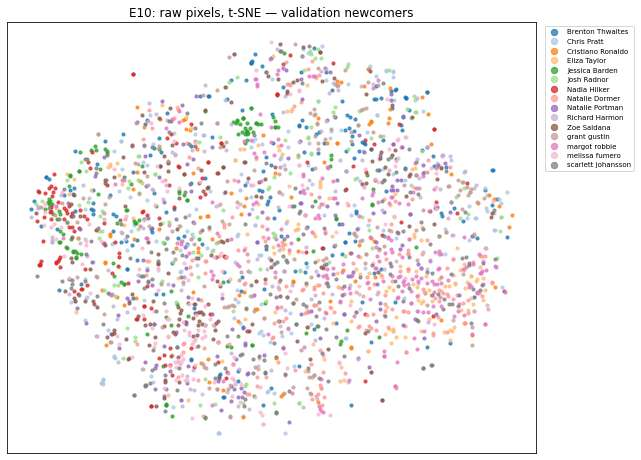

In [39]:
splits_file = BASE / "splits.json"
if splits_file.exists():
    groups = json.loads(splits_file.read_text())["people"]
    map_people = sorted(p for p, g in groups.items() if g == "val_newcomer")
    map_label = "validation newcomers"
else:
    rng = np.random.default_rng(SEED)
    all_people = sorted(meta.loc[ok, "person"].unique())
    map_people = sorted(rng.choice(all_people, size=min(15, len(all_people)), replace=False))
    map_label = "PREVIEW: 15 random people (re-run after Phase 4)"

sub = meta[ok & meta["person"].isin(map_people)]

def gray_vector(path, size=64):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA).ravel().astype(np.float32) / 255.0

X = np.stack([gray_vector(p) for p in tqdm(sub["path"], desc="E10 raw pixels")])
X50 = PCA(n_components=min(50, len(X) - 1), random_state=SEED).fit_transform(X)
xy = TSNE(n_components=2, init="pca", perplexity=min(30, (len(X) - 1) // 3),
          random_state=SEED).fit_transform(X50)

fig, ax = plt.subplots(figsize=(9, 6.5))
cmap = plt.get_cmap("tab20")
for k, person in enumerate(map_people):
    m = (sub["person"] == person).to_numpy()
    ax.scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.75, color=cmap(k % 20), label=person)
ax.set(title=f"E10: raw pixels, t-SNE — {map_label}", xticks=[], yticks=[])
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=7, markerscale=2)
plt.tight_layout(); save_fig("E10_raw_pixel_map"); plt.show()

##### EDA Summary (what gets removed during preprocessing)
###### Every flag from E1–E10 in one table, with the decision made after looking at the photos. **Nothing is removed here**; B1 does the removing.
###### Rule: remove what is *broken or wrong*; keep what is only *difficult* (side profiles, sunglasses, bad lighting).


In [40]:
flags = pd.DataFrame({
    "Unreadable or not an image":         ~ok,
    "Extra copy, same person (E6)":       meta["flag_duplicate"],
    "Same photo under two people (E6)":   meta["flag_cross_person_dup"],
    "No frontal face found (E8)":         ok & (meta["n_faces"] == 0),
    "Two or more faces (E8)":             ok & (meta["n_faces"] >= 2),
    "Very dark or very bright (E4)":      ok & ((meta["brightness"] < 40) | (meta["brightness"] > 215)),
    "Black-and-white (E4/E5)":            ok & (meta["colourfulness"] < 2),
    "Wrong person (E8 spot check)":       meta["flag_wrong_person"],
})
summary = flags.sum().rename("images flagged").to_frame()
summary["people affected"] = [meta.loc[flags[c], "person"].nunique() for c in flags.columns]
summary["decision"] = ["remove", "remove extra copies (keep one)", "remove both copies",
                       "keep: detector missed", "keep: false detections",
                       "keep: still usable faces", "keep: greyscale augmentation (B6)", "remove"]
display(summary)

definite = flags[["Unreadable or not an image", "Extra copy, same person (E6)",
                  "Same photo under two people (E6)", "Wrong person (E8 spot check)"]].any(axis=1)
left = meta[~definite].groupby("person").size()
print(f"Images left after removing the definite problems: {(~definite).sum():,}")
print(f"Smallest folder after removal: {left.min()} | imbalance ratio: {left.max() / left.min():.2f}")

,images flagged,people affected,decision
Unreadable or not an image,0,0,remove
"Extra copy, same person (E6)",136,61,remove extra copies (keep one)
Same photo under two people (E6),2,2,remove both copies
No frontal face found (E8),1784,104,keep: detector missed
Two or more faces (E8),104,57,keep: false detections
Very dark or very bright (E4),99,42,keep: still usable faces
Black-and-white (E4/E5),1316,103,keep: greyscale augmentation (B6)
Wrong person (E8 spot check),0,0,remove


Images left after removing the definite problems: 17,396
Smallest folder after removal: 86 | imbalance ratio: 2.71


In [41]:
meta_out = meta.copy()
meta_out.to_csv(DATA_DIR / "meta.csv", index=False)
flags.assign(path=meta["path"], person=meta["person"]).to_csv(DATA_DIR / "eda_flags.csv", index=False)
print("Saved:", DATA_DIR / "meta.csv", "and", DATA_DIR / "eda_flags.csv")
print("Figures saved in:", FIG_DIR)

Saved: /home/francois/projects/author_bot/part3_face_check/data/meta.csv and /home/francois/projects/author_bot/part3_face_check/data/eda_flags.csv
Figures saved in: /home/francois/projects/author_bot/part3_face_check/figures


###### EDA SUMMARY: what each check found and where it is used next

<div style="font-size: 0.6em">

| EDA check | Key findings | What happens next |
|---|---|---|
| **1. File check** | All 17,534 files open; all are real JPEGs in RGB; no wrong extensions | Nothing to fix. Every file can go straight into the pipeline |
| **2. Photos per person** | 105 people; 86–237 photos each (median 169); largest ÷ smallest = 2.76; smallest is Lionel Messi (86) | **Class balance:** no class weights needed (ratio under 3). **Split by person:** deal people into groups by photo count so every group gets big and small folders |
| **3. Image sizes** | Median 175 × 185 px; almost square (width ÷ height ≈ 0.94); 26% have a shortest side under 128 px; smallest is 80 px | **Image size:** resize everything to 128 × 128 by stretching (the shape barely changes) |
| **4. Pixel check** | 97 very dark, 2 very bright, 18 very flat, 1,316 black-and-white photos (7.5%) | Keep them all; they are hard but real. **Augmentation:** brightness and contrast changes, occasional greyscale |
| **5. Shortcut check** | Photo properties alone (no face) guess the person 4.7× better than chance (4.2× without width and height); most unusual: Jessica Barden (blurry, flat), Adriana Lima (large photos), Shakira (bright, colourful); up to 28% black-and-white for one person (Robert De Niro) | Small shortcut risk. **Augmentation** blurs these differences. **Error analysis:** check whether these people and grey or blurry photos show up among the mistakes |
| **6. Duplicate check** | 136 extra copies of the same photo within a person (61 people); the same photo filed under Selena Gomez and Zendaya; other cross-person matches were only similar framing | **Cleaning:** keep one photo per duplicate group; remove both Selena Gomez / Zendaya copies |
| **7. Looking at the photos** | Crops are tight and consistent (the average face is sharp); many people have several photos from the same shoot | **Cropping:** no re-cropping needed. **Split by person:** same-shoot photos can make staff validation accuracy look better than it is |
| **8. Face count check** | 15,646 photos with 1 face (89%); 1,784 with none (mostly side profiles the detector missed); 104 with 2+ (mostly false detections); spot check found 0 wrong-person photos | Keep all of them. **Door check:** crop the door photo the same way; ask for a straight-on look and retry if no face is found |
| **9. Who is in the dataset** | 105 celebrities (actors, models, musicians); mostly professional, well-lit photos | Results may be better than with everyday staff photos. Test on real staff photos before use |
| **10. Raw pixel map** | Preview on 15 random people: *(write what you saw: grouped by person, or by lighting and pose?)* | Re-run on the validation newcomers after the split. **Fingerprints:** draw the same map from CNN fingerprints and compare |

**After cleaning:** 17,396 photos left · smallest folder 86 · largest ÷ smallest = 2.71

</div>

#### Data Preprocessing - PART1 (Choosing which images to use and where)
---
###### Nothing touches pixels yet. These cells only decide **which files** are used and **who** is in which group.
###### 1. **Cleaning:** remove the definite problems found in the EDA.
###### 2. **Split by person:** 75 staff / 15 validation newcomers / 15 test newcomers.
###### 3. **Staff photo split:** the 75 staff's photos are split 70/15/15 into train / val / test for the classifier.

##### Clean clear errors from EDA

In [42]:
# Reload from disk so this section works even after a kernel restart (no need to re-run EDA)
meta = pd.read_csv(DATA_DIR / "meta.csv")

remove = (~meta["ok"].astype(bool)
          | meta["flag_duplicate"].astype(bool) # extra copies, same person (E6)
          | meta["flag_cross_person_dup"].astype(bool) # Selena Gomez / Zendaya pair (E6)
          | meta["flag_wrong_person"].astype(bool)) # spot check (E8)

clean = meta.loc[~remove, ["path", "person"]].reset_index(drop=True)
print(f"Started with {len(meta):,} photos | removed {int(remove.sum())} | kept {len(clean):,}")
print(f"People: {clean['person'].nunique()}")

Started with 17,534 photos | removed 138 | kept 17,396
People: 105


##### Split by person

In [43]:
SPLITS_FILE = BASE / "splits.json"
counts = clean.groupby("person").size().sort_values(ascending=False) # biggest folders first

if SPLITS_FILE.exists():
    groups = json.loads(SPLITS_FILE.read_text())["people"]
    print("Loaded the existing splits.json (NOT re-shuffled)")
else:
    # Deal like cards: walk down the list 7 people at a time (105 / 7 = 15 "tables").
    # At every table, 5 people become staff, 1 a validation newcomer, 1 a test newcomer.
    # People at the same table have similar folder sizes, so every group gets big AND small folders.
    rng = np.random.default_rng(SEED)
    hand = ["staff"] * 5 + ["val_newcomer", "test_newcomer"]
    names = counts.index.to_list()
    groups = {}
    for start in range(0, len(names), 7):
        table = names[start:start + 7]
        roles = rng.permutation(hand)[:len(table)]
        for person, role in zip(table, roles):
            groups[person] = str(role)
    SPLITS_FILE.write_text(json.dumps({"seed": SEED, "people": groups}, indent=2))
    print("Created splits.json")

clean["group"] = clean["person"].map(groups)
assert clean["group"].notna().all(), "Someone in clean has no group - delete splits.json and re-run"

Loaded the existing splits.json (NOT re-shuffled)


##### Check that groups are fair

In [44]:
per_group = clean.groupby("group").agg(people=("person", "nunique"), photos=("path", "size"))
per_person = clean.groupby(["group", "person"]).size().groupby("group").agg(["min", "median", "max"])
display(per_group.join(per_person).loc[["staff", "val_newcomer", "test_newcomer"]])

,people,photos,min,median,max
group,,,,,
staff,75,12434,86,168.0,233
val_newcomer,15,2469,98,166.0,219
test_newcomer,15,2493,101,171.0,224


##### Split STAFF images 70/15/15
###### a random shuffle could leave a small-folder person (like Messi, with 86 photos) with almost nothing in validation. Splitting per person guarantees everyone shows up in all three parts.

In [45]:
staff = clean[clean["group"] == "staff"].copy()

# The CNN outputs numbers 0-74, not names. CLASS_NAMES[i] turns number i back into a name.
CLASS_NAMES = sorted(staff["person"].unique())
staff["label"] = staff["person"].map({name: i for i, name in enumerate(CLASS_NAMES)})

# Split EACH person 70/15/15, so every staff member appears in train, val and test
parts = []
for person, df in staff.groupby("person"):
    df = df.sample(frac=1, random_state=SEED) # shuffle this person's photos
    n = len(df)
    n_train = round(n * 0.70)
    n_val = round(n * 0.15)
    df["split"] = ["train"] * n_train + ["val"] * n_val + ["test"] * (n - n_train - n_val)
    parts.append(df)
staff = pd.concat(parts, ignore_index=True)

print(staff["split"].value_counts().reindex(["train", "val", "test"]).to_string())
print("\nSmallest number of photos any one person has in each part:")
print(staff.groupby(["split", "person"]).size().groupby("split").min()
           .reindex(["train", "val", "test"]).to_string())

staff.to_csv(DATA_DIR / "staff_split.csv", index=False)
clean[clean["group"] != "staff"].to_csv(DATA_DIR / "newcomers.csv", index=False)
(DATA_DIR / "class_names.json").write_text(json.dumps(CLASS_NAMES, indent=2))
print(f"\nSaved staff_split.csv ({len(staff):,} rows), newcomers.csv, class_names.json ({len(CLASS_NAMES)} names)")

split
train    8702
val      1865
test     1867

Smallest number of photos any one person has in each part:
split
train    60
val      13
test     13

Saved staff_split.csv (12,434 rows), newcomers.csv, class_names.json (75 names)


#### Data Preprocessing - PART2 (Turning each image into numbers)
---

<div style="font-size: 0.6em">

A `tf.data` pipeline reads each photo, resizes it and groups photos into batches for the GPU.
**Training photos only** are augmented (randomly changed) so the CNN sees a slightly different version of each photo every epoch. Validation and test photos are never changed, so their scores stay fair.

| Step | What | Why (EDA finding) |
|---|---|---|
| Resize | 128 × 128, stretched | Photos are almost square (image sizes) |
| Colour jitter | Brightness, contrast, saturation; 10% become greyscale | Dark, flat and black-and-white photos exist; weakens the photo-property shortcut (pixel check, shortcut check) |
| Move and flip | Mirror, small rotation, zoom and shift | Crops are tight but faces sit slightly differently (looking at the photos) |

</div>

##### Settings and data

In [46]:
IMG_SIZE = 128 # every photo becomes 128 x 128 pixels
BATCH_SIZE = 64 # photos the GPU processes at once (fits easily in 8 GB)
AUTOTUNE = tf.data.AUTOTUNE # let TensorFlow choose how many CPU threads prepare photos

RETRAIN = False # False = use the saved models. True = train v1 and v2 again (about 30 min, numbers will shift slightly). ONLY set after v2 was trained and saved once, otherwise v2 will be trained from scratch and take hours.

staff = pd.read_csv(DATA_DIR / "staff_split.csv")
CLASS_NAMES = json.loads((DATA_DIR / "class_names.json").read_text())
NUM_CLASSES = len(CLASS_NAMES)
print(f"{len(staff):,} staff photos | {NUM_CLASSES} people")

12,434 staff photos | 75 people


##### Load one photo
###### most photos are bigger than 128 px, and shrinking without antialiasing makes jagged edges. Pixels stay in the 0–255 range here. Scaling to 0–1 will happen inside the model (a Rescaling layer), so the door check gets exactly the same scaling for free.

In [47]:
def load_image(path, label):
    """File path -> 128 x 128 x 3 array of pixels (0-255)."""
    raw = tf.io.read_file(path) # the file's bytes
    img = tf.io.decode_jpeg(raw, channels=3) # bytes -> pixels (RGB, unlike cv2's BGR)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE], antialias=True) # stretch to 128 x 128
    return img, label

##### Augmentation
###### tf.image.random_brightness on a whole batch would brighten all 64 photos by the same amount, so the colour changes are applied one photo at a time. The Keras layers already give each photo in a batch its own random amount, so they run on whole batches, which is faster.

In [48]:
GREY_CHANCE = 0.10      # 1 in 10 training photos becomes black-and-white

def colour_jitter(img, label):
    """Random colour changes, a different amount for every photo."""
    img = tf.image.random_brightness(img, max_delta=25)       # lighter or darker by up to 25
    img = tf.image.random_contrast(img, 0.8, 1.2)             # flatter or punchier
    img = tf.image.random_saturation(img, 0.8, 1.2)           # less or more colourful
    grey = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(img))
    img = tf.where(tf.random.uniform([]) < GREY_CHANCE, grey, img)   # sometimes use the grey version
    img = tf.clip_by_value(img, 0.0, 255.0)                    # keep pixels inside 0-255
    return img, label

# Keras layers that move the face around a little. Each photo in a batch gets its own random amount.
move_and_flip = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),       # mirror left-right (a face is roughly symmetric)
    tf.keras.layers.RandomRotation(0.03),           # tilt up to about 11 degrees
    tf.keras.layers.RandomZoom(0.10),               # zoom in or out up to 10%
    tf.keras.layers.RandomTranslation(0.05, 0.05),  # shift up to 5% up/down/left/right
], name="move_and_flip")

##### Build the three datasets

In [49]:
def make_dataset(split, training):
    df = staff[staff["split"] == split]
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["label"].values))
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True) # new order every epoch
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(colour_jitter, num_parallel_calls=AUTOTUNE) # colour changes BEFORE batching, so each photo gets its own random amount
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda x, y: (move_and_flip(x, training=True), y), num_parallel_calls=AUTOTUNE) # movement layers run on whole batches; training=True switches the random changes on
    return ds.prefetch(AUTOTUNE)    # prepare the next batch while the GPU works on this one

train_ds = make_dataset("train", training=True)
val_ds   = make_dataset("val",   training=False)
test_ds  = make_dataset("test",  training=False)

images, labels = next(iter(train_ds))
print("One batch:", images.shape, images.dtype, "| labels:", labels.shape, labels.dtype)
print(f"Pixel range: {float(tf.reduce_min(images)):.1f} to {float(tf.reduce_max(images)):.1f}")

One batch: (64, 128, 128, 3) <dtype: 'float32'> | labels: (64,) <dtype: 'int64'>
Pixel range: 0.0 to 255.0


##### Look at what the CNN will see

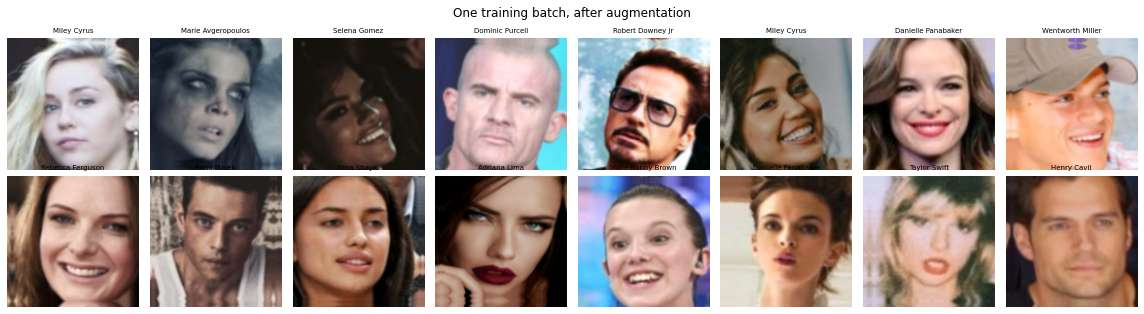

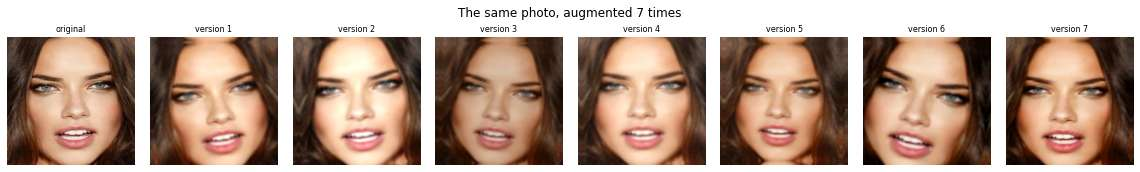

In [50]:
# 16 photos from one training batch
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, img, lab in zip(axes.ravel(), images[:16], labels[:16]):
    ax.imshow(img.numpy().astype("uint8"))
    ax.set_title(CLASS_NAMES[int(lab)], fontsize=7)
    ax.axis("off")
plt.suptitle("One training batch, after augmentation"); plt.tight_layout()
save_fig("pipeline_train_batch"); plt.show()

# One photo, augmented 7 different ways: is the augmentation too weak, too strong, or about right?
one_path = staff.loc[staff["split"] == "train", "path"].iloc[0]
img, _ = load_image(one_path, 0)
copies = tf.stack([colour_jitter(img, 0)[0] for _ in range(7)])
copies = move_and_flip(copies, training=True)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, im, title in zip(axes, [img] + list(copies), ["original"] + [f"version {i}" for i in range(1, 8)]):
    ax.imshow(im.numpy().astype("uint8")); ax.set_title(title, fontsize=8); ax.axis("off")
plt.suptitle("The same photo, augmented 7 times"); plt.tight_layout()
save_fig("pipeline_one_photo_augmented"); plt.show()

#### Build and Train the CNN
---
###### The CNN learns to name the 75 staff. Naming them is only the **training task**: the real goal is the 128-number `fingerprint` layer just before the name picker. Later the name picker is removed and the fingerprint is used for the door check.

<div style="font-size: 0.6em">

| Part | What it does |
|---|---|
| Rescaling | Pixels 0–255 → 0–1 (inside the model, so the door check gets the same scaling) |
| 4 conv blocks (32 → 64 → 128 → 256 filters) | Early blocks find edges and textures; later blocks find eyes, noses, face shapes. Each block halves the image size |
| Global average pooling | Turns the 8 × 8 × 256 block output into 256 numbers |
| Dropout 30% | Randomly switches off neurons during training so the model can't memorise |
| **fingerprint** (128) | The face summary we keep |
| name_picker (75, softmax) | 75 probabilities, one per staff member. Thrown away after training |

</div>

##### Build the model

In [51]:
MODEL_DIR = BASE / "models"

def conv_block(x, filters):
    """Two 3x3 convolutions, then halve the image size."""
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)   # 3x3 filters scan the image
    x = layers.BatchNormalization()(x)                                 # keeps values in a stable range
    x = layers.ReLU()(x)                                               # negative values -> 0
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)   # a second look at the same size
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)                                       # keep the strongest signal in each 2x2 -> half size
    return x

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="photo")

x = layers.Rescaling(1 / 255)(inputs) # pixels 0-255 -> 0-1, inside the model so the door uses the same scaling

for filters in (32, 64, 128, 256): # 128 -> 64 -> 32 -> 16 -> 8 pixels across
    
    x = conv_block(x, filters)

x = layers.GlobalAveragePooling2D()(x) # 8 x 8 x 256 -> 256 numbers (the average of each feature map)

x = layers.Dropout(0.3)(x) # switch off 30% of values during training so the model can't memorise

fingerprint = layers.Dense(128, name="fingerprint")(x) # THE FACE FINGERPRINT: kept after training; named so we can cut the model here

outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="name_picker")(fingerprint) # 75 probabilities, removed after training

model = tf.keras.Model(inputs, outputs, name="face_cnn")
model.summary(line_length=90)

Model: "face_cnn"
__________________________________________________________________________________________
 Layer (type)                           Output Shape                        Param #       
 photo (InputLayer)                     [(None, 128, 128, 3)]               0             
                                                                                          
 rescaling (Rescaling)                  (None, 128, 128, 3)                 0             
                                                                                          
 conv2d (Conv2D)                        (None, 128, 128, 32)                864           
                                                                                          
 batch_normalization (BatchNormalizati  (None, 128, 128, 32)                128           
 on)                                                                                      
                                                                        

##### Catch wrong labels or class counts before training

In [52]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss="sparse_categorical_crossentropy", # labels are plain numbers 0-74
              metrics=["accuracy"])

# An untrained model should be guessing evenly across 75 people.
# Its loss should then be about ln(75). If it's far off, something is wired wrong.
images, labels = next(iter(val_ds))
loss, acc = model.evaluate(images, labels, verbose=0)
print(f"Untrained loss: {loss:.2f} (expected about ln({NUM_CLASSES}) = {np.log(NUM_CLASSES):.2f})")
print(f"Untrained accuracy: {acc:.3f} (chance = {1 / NUM_CLASSES:.3f})")

Untrained loss: 4.32 (expected about ln(75) = 4.32)
Untrained accuracy: 0.000 (chance = 0.013)


##### TRAIN 

In [53]:
EPOCHS = 60       # an upper limit: early stopping usually ends training sooner

callbacks = [
    # Stop when validation loss hasn't improved for 8 epochs, and go back to the best epoch
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    # When progress stalls for 3 epochs, halve the learning rate (smaller, more careful steps)
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    # Save the best model to disk, so a crash or kernel restart doesn't lose it
    tf.keras.callbacks.ModelCheckpoint(str(MODEL_DIR / "face_cnn.keras"), monitor="val_loss", save_best_only=True),
    # Save every epoch's numbers, so the curves can be re-drawn without retraining
    tf.keras.callbacks.CSVLogger(str(MODEL_DIR / "training_log.csv")),
]

if RETRAIN or not (MODEL_DIR / "face_cnn.keras").exists():
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)
else:
    print("Using the saved face_cnn.keras (set RETRAIN = True in 'Settings and data' to train again)")

Using the saved face_cnn.keras (set RETRAIN = True in 'Settings and data' to train again)


##### Training curves

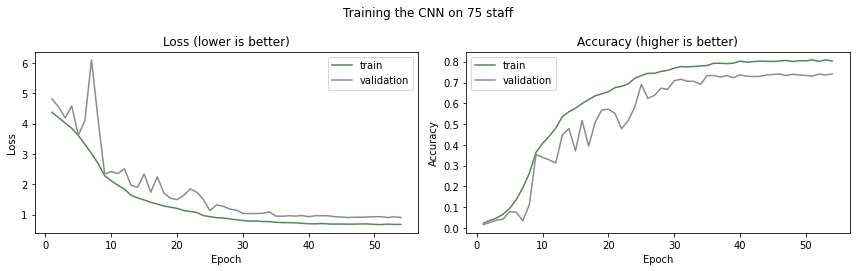

Best epoch: 46 | val loss 0.903 | val accuracy 0.741


In [54]:
log = pd.read_csv(MODEL_DIR / "training_log.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(log["epoch"] + 1, log["loss"], color=GREEN, label="train")
axes[0].plot(log["epoch"] + 1, log["val_loss"], color=GREY, label="validation")
axes[0].set(xlabel="Epoch", ylabel="Loss", title="Loss (lower is better)"); axes[0].legend()
axes[1].plot(log["epoch"] + 1, log["accuracy"], color=GREEN, label="train")
axes[1].plot(log["epoch"] + 1, log["val_accuracy"], color=GREY, label="validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy (higher is better)"); axes[1].legend()
plt.suptitle("Training the CNN on 75 staff"); plt.tight_layout()
save_fig("training_curves"); plt.show()

best = log["val_loss"].idxmin()
print(f"Best epoch: {best + 1} | val loss {log.loc[best, 'val_loss']:.3f} | val accuracy {log.loc[best, 'val_accuracy']:.3f}")

##### Health check on staff test photos

In [55]:
model = tf.keras.models.load_model(str(MODEL_DIR / "face_cnn.keras")) # the best saved version
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Staff test photos: accuracy {test_acc:.3f} | loss {test_loss:.3f} | chance {1 / NUM_CLASSES:.3f}")

Staff test photos: accuracy 0.754 | loss 0.904 | chance 0.013


#### Feature extraction + Embedding
---
###### The trained CNN names 75 staff. Cutting it off at the `fingerprint` layer gives a model that turns **any** face photo into 128 numbers.
###### Each fingerprint is then scaled to length 1, so comparing two faces is one multiplication: the **cosine similarity**.
###### 1 = pointing the same way (same face) · 0 = unrelated · negative = opposite.

###### **The test that matters:** do the fingerprints still work on the **validation newcomers**, 15 people the CNN has never seen?
###### The test newcomers stay untouched until the final door test.

##### Remove/Cut the name picker
###### fingerprint_maker shares the exact same layers as model. It just hands back the output from one layer earlier. Dropout switches itself off automatically when predicting, so the same photo always gives the same fingerprint.

In [56]:
# Same layers and the same trained weights, but the model now stops at the fingerprint layer
fingerprint_maker = tf.keras.Model(inputs=model.input,
                                   outputs=model.get_layer("fingerprint").output,
                                   name="fingerprint_maker")
fingerprint_maker.save(str(MODEL_DIR / "fingerprint_maker.keras"))

print("Input: ", fingerprint_maker.input_shape)
print("Output:", fingerprint_maker.output_shape)

Input:  (None, 128, 128, 3)
Output: (None, 128)


##### Fingerprints for the validation newcomers

In [57]:
def get_fingerprints(paths):
    """Photo paths -> one fingerprint per photo, each scaled to length 1."""
    ds = (tf.data.Dataset.from_tensor_slices(list(paths))
          .map(lambda p: load_image(p, 0)[0], num_parallel_calls=AUTOTUNE) # same loading as training, no augmentation
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))
    fps = fingerprint_maker.predict(ds, verbose=0)
    return fps / np.linalg.norm(fps, axis=1, keepdims=True) # scale every fingerprint to length 1

newcomers = pd.read_csv(DATA_DIR / "newcomers.csv")
val_nc = newcomers[newcomers["group"] == "val_newcomer"].reset_index(drop=True)
val_fps = get_fingerprints(val_nc["path"])

print(f"Validation newcomers: {val_nc['person'].nunique()} people, {len(val_nc):,} photos")
print("Fingerprints:", val_fps.shape, "| length of the first one:", round(float(np.linalg.norm(val_fps[0])), 3))

Validation newcomers: 15 people, 2,469 photos
Fingerprints: (2469, 128) | length of the first one: 1.0


##### Same person against different people

Same person:         210,273 pairs | average similarity 0.674
Different people:  2,836,473 pairs | average similarity 0.224


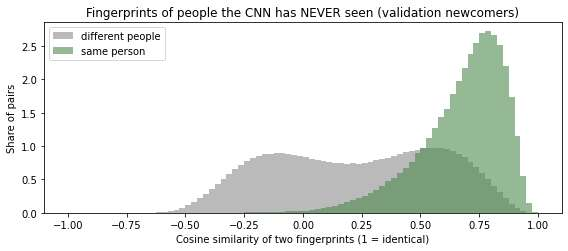

In [58]:
sim = val_fps @ val_fps.T  # similarity of every photo with every other photo
people = val_nc["person"].to_numpy()
same_person = people[:, None] == people[None, :]  # True where both photos are the same person
upper = np.triu(np.ones_like(sim, dtype=bool), k=1) # each pair once, and never a photo with itself

same_scores = sim[upper & same_person]
diff_scores = sim[upper & ~same_person]
print(f"Same person:       {len(same_scores):>9,} pairs | average similarity {same_scores.mean():.3f}")
print(f"Different people:  {len(diff_scores):>9,} pairs | average similarity {diff_scores.mean():.3f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(-1, 1, 81)
ax.hist(diff_scores, bins=bins, density=True, alpha=0.6, color=GREY, label="different people")
ax.hist(same_scores, bins=bins, density=True, alpha=0.6, color=GREEN, label="same person")
ax.set(xlabel="Cosine similarity of two fingerprints (1 = identical)", ylabel="Share of pairs",
       title="Fingerprints of people the CNN has NEVER seen (validation newcomers)")
ax.legend(); plt.tight_layout(); save_fig("fingerprints_similarity_val"); plt.show()

##### The fingerprint map

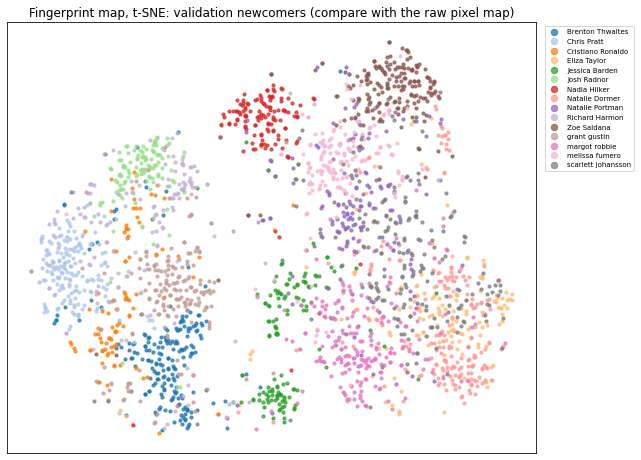

In [59]:
xy = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED).fit_transform(val_fps)

fig, ax = plt.subplots(figsize=(9, 6.5))
cmap = plt.get_cmap("tab20")
for k, person in enumerate(sorted(val_nc["person"].unique())):
    m = (val_nc["person"] == person).to_numpy()
    ax.scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.75, color=cmap(k % 20), label=person)
ax.set(title="Fingerprint map, t-SNE: validation newcomers (compare with the raw pixel map)", xticks=[], yticks=[])
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=7, markerscale=2)
plt.tight_layout(); save_fig("fingerprint_map_val"); plt.show()

#### New employees & the door THRESHOLD (validation newcomers only)
---
###### Simulating the bookstore on 15 people the CNN has never seen:
###### - **8 people are enrolled** as new staff: 5 photos each → their fingerprints are averaged into one **template**. No retraining.
###### - **The other 7 play strangers.**
###### - Every remaining photo "walks up to the door": its fingerprint is compared with all 8 templates, and the **best match score** decides.
###### - **Score ≥ threshold → "Welcome, name" · below → "Please go to reception".**

###### Which 8 are staff and which 5 photos are used is random, so the simulation is repeated **20 times** with different picks and all door visits are pooled.
###### Rule for choosing the threshold: **at most 1% of strangers may get in.** Letting a stranger in is worse than sending a staff member to reception.

##### Enrol 'NewEmployee' + simulate door

In [60]:
N_ENROLLED = 8      # validation newcomers who become "staff" in each round (the other 7 are strangers)
N_ENROL_PHOTOS = 5  # photos taken of each new staff member on their first day
N_ROUNDS = 20       # repeat with different random picks so one lucky/unlucky split doesn't decide

def enrol(fps, people_arr, who, rng):
    """Average 5 random fingerprints per person into one template. Returns names, templates,
    and which photos were used (those never come back to the door)."""
    names, templates = [], []
    used = np.zeros(len(people_arr), dtype=bool)
    for person in who:
        idx = np.flatnonzero(people_arr == person)
        pick = rng.choice(idx, size=N_ENROL_PHOTOS, replace=False)
        used[pick] = True
        template = fps[pick].mean(axis=0)
        templates.append(template / np.linalg.norm(template)) # back to length 1
        names.append(person)
    return np.array(names), np.stack(templates), used

def door_round(fps, people_arr, rng):
    """One simulated round: enrol some people, then send every other photo to the door."""
    everyone = np.unique(people_arr)
    staff_now = rng.choice(everyone, size=N_ENROLLED, replace=False)
    names, gallery, used = enrol(fps, people_arr, staff_now, rng)
    at_door = ~used
    scores = fps[at_door] @ gallery.T # each visitor against all 8 templates
    return pd.DataFrame({
        "person": people_arr[at_door],
        "is_staff": np.isin(people_arr[at_door], staff_now),
        "best_match": names[scores.argmax(axis=1)], # the closest template
        "best_score": scores.max(axis=1), # how close
    })

rng = np.random.default_rng(SEED)
val_people = val_nc["person"].to_numpy()
visits = pd.concat([door_round(val_fps, val_people, rng).assign(round=r) for r in range(N_ROUNDS)],
                   ignore_index=True)

visits["right_name"] = visits["best_match"] == visits["person"] # True when the closest template is the visitor's own (matters for staff)

print(f"{N_ROUNDS} rounds | {len(visits):,} door visits "
      f"({visits['is_staff'].sum():,} by staff, {(~visits['is_staff']).sum():,} by strangers)")
print(f"Average best score - staff: {visits.loc[visits.is_staff, 'best_score'].mean():.3f} | "
      f"strangers: {visits.loc[~visits.is_staff, 'best_score'].mean():.3f}")

20 rounds | 48,580 door visits (25,237 by staff, 23,343 by strangers)
Average best score - staff: 0.808 | strangers: 0.732


##### Try every threshold (Lowest threshold that keeps strangers under the limit)

In [61]:
def door_outcomes(visits, threshold):
    """What share of visits end each way at this threshold."""
    welcomed = visits["best_score"] >= threshold
    staff = visits["is_staff"]
    return {
        "staff welcomed (right name)": (staff & welcomed & visits["right_name"]).sum() / staff.sum(),
        "staff welcomed (WRONG name)": (staff & welcomed & ~visits["right_name"]).sum() / staff.sum(),
        "staff sent to reception":     (staff & ~welcomed).sum() / staff.sum(),
        "strangers let in":            (~staff & welcomed).sum() / (~staff).sum(),
    }

thresholds = np.round(np.arange(0, 1.0001, 0.005), 3)       # 0.000, 0.005, ... 1.000
sweep = pd.DataFrame([door_outcomes(visits, t) for t in thresholds], index=thresholds)
sweep.index.name = "threshold"

# The trade-off in one table: the lowest threshold that keeps strangers under each limit
rows = {}
for cap in (0.005, 0.01, 0.02, 0.05):

    t = sweep.index[sweep["strangers let in"] <= cap].min() # LOWEST threshold that keeps strangers under the cap = welcomes the most staff

    rows[f"strangers let in <= {cap:.1%}"] = {"threshold": t, **sweep.loc[t]}
table = pd.DataFrame(rows).T
pct_cols = [c for c in table.columns if c != "threshold"]
table[pct_cols] = (table[pct_cols] * 100).round(1)
display(table.rename(columns={c: c + " %" for c in pct_cols}))

,threshold,staff welcomed (right name) %,staff welcomed (WRONG name) %,staff sent to reception %,strangers let in %
strangers let in <= 0.5%,0.940,2.9,0.2,96.9,0.4
strangers let in <= 1.0%,0.930,5.1,0.4,94.5,0.8
strangers let in <= 2.0%,0.915,9.5,1.0,89.5,1.9
strangers let in <= 5.0%,0.895,16.6,2.5,81.0,4.7


#### FIX 1 (centre the fingerprints)
---
###### At a 1% stranger limit only about 5% of staff were welcomed: strangers' best scores (0.73) sit almost on top of staff scores (0.81).All fingerprints share a common "average face" direction, which makes every pair look similar.**Fix:** subtract the average fingerprint of the *staff training photos* before scaling to length 1, so only what makes each person different is compared.No retraining, and no newcomer photos are used to compute the average (no leakage).The same random seed is used, so both versions are tested on exactly the same staff/stranger picks.

In [62]:
def get_raw_fingerprints(paths):
    """Like get_fingerprints, but WITHOUT scaling to length 1."""
    ds = (tf.data.Dataset.from_tensor_slices(list(paths))
          .map(lambda p: load_image(p, 0)[0], num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))
    return fingerprint_maker.predict(ds, verbose=0)

def simulate_door(fps):
    """The same 20-round door simulation as above. Same seed -> same picks every time."""
    rng = np.random.default_rng(SEED)
    v = pd.concat([door_round(fps, val_people, rng).assign(round=r) for r in range(N_ROUNDS)],
                  ignore_index=True)
    v["right_name"] = v["best_match"] == v["person"]
    return v

def summary_at(visits, max_strangers_in):
    """Lowest threshold meeting the stranger limit, and what happens at it (in %)."""
    sweep = pd.DataFrame([door_outcomes(visits, t) for t in thresholds], index=thresholds)
    t = sweep.index[sweep["strangers let in"] <= max_strangers_in].min()
    return {"threshold": t, **{k: round(v * 100, 1) for k, v in sweep.loc[t].items()}}

# The "average face": mean fingerprint of the staff TRAINING photos only
MEAN_FP = get_raw_fingerprints(staff.loc[staff["split"] == "train", "path"]).mean(axis=0)
np.save(MODEL_DIR / "mean_fingerprint.npy", MEAN_FP)

centred = get_raw_fingerprints(val_nc["path"]) - MEAN_FP
val_fps_c = centred / np.linalg.norm(centred, axis=1, keepdims=True)
visits_c = simulate_door(val_fps_c)

print("Average best score at the door:")
print(f"  before - staff {visits.loc[visits.is_staff, 'best_score'].mean():.3f} | "
      f"strangers {visits.loc[~visits.is_staff, 'best_score'].mean():.3f}")
print(f"  after  - staff {visits_c.loc[visits_c.is_staff, 'best_score'].mean():.3f} | "
      f"strangers {visits_c.loc[~visits_c.is_staff, 'best_score'].mean():.3f}")

display(pd.DataFrame({
    "before, strangers <= 1%":  summary_at(visits, 0.01),
    "after, strangers <= 1%":   summary_at(visits_c, 0.01),
    "before, strangers <= 5%":  summary_at(visits, 0.05),
    "after, strangers <= 5%":   summary_at(visits_c, 0.05),
}).T)

Average best score at the door:
  before - staff 0.808 | strangers 0.732
  after  - staff 0.728 | strangers 0.624


,threshold,staff welcomed (right name),staff welcomed (WRONG name),staff sent to reception,strangers let in
"before, strangers <= 1%",0.930,5.1,0.4,94.5,0.8
"after, strangers <= 1%",0.905,6.3,0.5,93.2,0.9
"before, strangers <= 5%",0.895,16.6,2.5,81.0,4.7
"after, strangers <= 5%",0.860,16.7,2.3,81.0,4.5


#### FIX 2 (retrain so the fingerprints are built for the door)
---
###### Fix 1 barely helped (5.1% → 6.3% of staff welcomed at 1%): the problem is that the fingerprints aren't distinctive enough.
###### The v1 CNN only had to pick the right name out of 75. It never had to keep different people **far apart**.

###### Three changes, everything else (data, pipeline, conv blocks) stays the same:
###### 1. **Cosine name picker:** fingerprints and the 75 "person directions" are scaled to length 1, so training compares faces exactly like the door does.
###### 2. **Margin (CosFace):** during training the right person's score is handicapped by 0.15, so the CNN must win clearly, pushing each person's fingerprints well away from everyone else's.
###### 3. **More patience:** halve the learning rate after 5 stalled epochs (was 3), stop after 12 (was 8).

###### The v1 model is kept. The new one is saved as `face_cnn_v2.keras`.

##### The cosine name picker and the margin loss

In [63]:
SCALE = 30.0   # cosines are only -1..1; multiplying by 30 gives the softmax enough range to be confident
MARGIN = 0.15  # the handicap on the right person's score during training

@tf.keras.utils.register_keras_serializable(package="facecheck") # lets Keras save and reload this layer
class CosineNamePicker(layers.Layer):
    """Replaces the softmax name picker: outputs the cosine between a fingerprint and each of the 75 people."""
    def __init__(self, n_classes, **kwargs):
        super().__init__(**kwargs)
        self.n_classes = n_classes

    def build(self, input_shape):
        # One learned direction per staff member (128 numbers each)
        self.w = self.add_weight(name="person_directions", shape=(input_shape[-1], self.n_classes),
                                 initializer="glorot_uniform", trainable=True)

    def call(self, fingerprint):
        f = tf.math.l2_normalize(fingerprint, axis=1)    # fingerprint -> length 1
        w = tf.math.l2_normalize(self.w, axis=0)         # each person's direction -> length 1
        return tf.matmul(f, w)                           # cosine with all 75 people at once

    def get_config(self): # tells Keras how to rebuild this layer when the saved model is loaded
        return {**super().get_config(), "n_classes": self.n_classes}

@tf.keras.utils.register_keras_serializable(package="facecheck")
def cosface_loss(y_true, cos):
    """Cross-entropy, but the right person's cosine is lowered by MARGIN first."""

    y = tf.one_hot(tf.cast(tf.reshape(y_true, [-1]), tf.int32), depth=tf.shape(cos)[-1]) # labels 0-74 -> rows like [0, 0, 1, 0, ...] so the margin hits ONLY the right person

    logits = SCALE * (cos - MARGIN * y) # handicap only the right answer
    
    return tf.keras.losses.categorical_crossentropy(y, logits, from_logits=True) # from_logits: softmax happens inside the loss

##### Build v2 and run the sanity check

In [64]:
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="photo")
x = layers.Rescaling(1 / 255)(inputs)
for filters in (32, 64, 128, 256): # the same conv_block as v1
    x = conv_block(x, filters)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
fingerprint = layers.Dense(128, name="fingerprint")(x)
outputs = CosineNamePicker(NUM_CLASSES, name="name_picker")(fingerprint)
model_v2 = tf.keras.Model(inputs, outputs, name="face_cnn_v2")

model_v2.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                 loss=cosface_loss,
                 metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")])

images, labels = next(iter(val_ds))
loss, acc = model_v2.evaluate(images, labels, verbose=0)

reference = SCALE * MARGIN + np.log(NUM_CLASSES - 1 + np.exp(-SCALE * MARGIN)) # If every cosine were 0: the right person scores -SCALE*MARGIN, the other 74 score 0 -> this is the expected loss

print(f"Untrained loss: {loss:.2f} (about {reference:.2f} if every cosine were 0; roughly 9-15 is normal)")
print(f"Untrained accuracy: {acc:.3f} (chance = {1 / NUM_CLASSES:.3f})")

Untrained loss: 13.82 (about 8.80 if every cosine were 0; roughly 9-15 is normal)
Untrained accuracy: 0.000 (chance = 0.013)


##### Train v2

In [65]:
EPOCHS_V2 = 80

callbacks_v2 = [
    # patience 12 (v1: 8): v2's validation is noisier, so wait longer before stopping
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True, verbose=1),
    # patience 5 (v1: 3): v1 cut its learning rate too early and stopped learning at 80% training accuracy
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(str(MODEL_DIR / "face_cnn_v2.keras"), monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.CSVLogger(str(MODEL_DIR / "training_log_v2.csv")),
]

if RETRAIN or not (MODEL_DIR / "face_cnn_v2.keras").exists():
    history_v2 = model_v2.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_V2,
                              callbacks=callbacks_v2, verbose=2)
else:
    print("Using the saved face_cnn_v2.keras (set RETRAIN = True in 'Settings and data' to train again)")

Using the saved face_cnn_v2.keras (set RETRAIN = True in 'Settings and data' to train again)


##### Door test 2 on validation newcomers

In [66]:
model_v2 = tf.keras.models.load_model(str(MODEL_DIR / "face_cnn_v2.keras")) # best saved epoch
test_loss, test_acc = model_v2.evaluate(test_ds, verbose=0)
print(f"v2 staff test photos: accuracy {test_acc:.3f} (v1 was 0.754)")

fingerprint_maker_v2 = tf.keras.Model(model_v2.input, model_v2.get_layer("fingerprint").output,
                                      name="fingerprint_maker_v2")
fingerprint_maker_v2.save(str(MODEL_DIR / "fingerprint_maker_v2.keras"))

def fingerprints_with(maker, paths):
    """Same as get_fingerprints, but you choose which fingerprint maker to use."""
    ds = (tf.data.Dataset.from_tensor_slices(list(paths))
          .map(lambda p: load_image(p, 0)[0], num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))
    fps = maker.predict(ds, verbose=0)
    return fps / np.linalg.norm(fps, axis=1, keepdims=True)

val_fps_v2 = fingerprints_with(fingerprint_maker_v2, val_nc["path"])
visits_v2 = simulate_door(val_fps_v2) # same seed -> the same staff/stranger picks as v1

print(f"v2 average best score - staff {visits_v2.loc[visits_v2.is_staff, 'best_score'].mean():.3f} | "
      f"strangers {visits_v2.loc[~visits_v2.is_staff, 'best_score'].mean():.3f}")

display(pd.DataFrame({
    "v1, strangers <= 1%":          summary_at(visits, 0.01),
    "v1 centred, strangers <= 1%":  summary_at(visits_c, 0.01),
    "v2, strangers <= 1%":          summary_at(visits_v2, 0.01),
    "v1, strangers <= 5%":          summary_at(visits, 0.05),
    "v1 centred, strangers <= 5%":  summary_at(visits_c, 0.05),
    "v2, strangers <= 5%":          summary_at(visits_v2, 0.05),
}).T)

v2 staff test photos: accuracy 0.894 (v1 was 0.754)
v2 average best score - staff 0.573 | strangers 0.412


,threshold,staff welcomed (right name),staff welcomed (WRONG name),staff sent to reception,strangers let in
"v1, strangers <= 1%",0.930,5.1,0.4,94.5,0.8
"v1 centred, strangers <= 1%",0.905,6.3,0.5,93.2,0.9
"v2, strangers <= 1%",0.725,15.8,0.5,83.7,0.9
"v1, strangers <= 5%",0.895,16.6,2.5,81.0,4.7
"v1 centred, strangers <= 5%",0.860,16.7,2.3,81.0,4.5
"v2, strangers <= 5%",0.640,33.9,2.4,63.7,5.0


#### Door settings: enrolment photos and door photos (validation newcomers, v2 fingerprints)
---
###### v2 is the model from here on (staff test accuracy 89.4%, staff welcomed at 1% strangers: 15.8%, up from 5.1%).
###### The last experiment changes only how the door is **used**, not the model:
###### - **Enrol 5 or 10 photos** per new staff member (a richer template)
###### - **Judge 1 or 3 photos** per door visit (a door camera takes several frames; their fingerprints are averaged)

###### Caveat: the 3 "door photos" here are different photos of the person, which vary more than real consecutive camera frames.
###### The 3-photo results are therefore **optimistic**.

In [67]:
def door_round_v3(fps, people_arr, rng, n_enrol, burst):
    """Like door_round, but you choose how many enrolment photos and how many photos per door visit."""
    everyone = np.unique(people_arr)
    staff_now = rng.choice(everyone, size=N_ENROLLED, replace=False)

    # Enrol: average n_enrol photos per new staff member
    names, gallery = [], []
    used = np.zeros(len(people_arr), dtype=bool)
    for person in staff_now:
        pick = rng.choice(np.flatnonzero(people_arr == person), size=n_enrol, replace=False)
        used[pick] = True
        t = fps[pick].mean(axis=0)
        gallery.append(t / np.linalg.norm(t))
        names.append(person)
    names, gallery = np.array(names), np.stack(gallery)

    # Door: each visit averages `burst` of the person's remaining photos (no photo is used twice)
    rows = []
    for person in everyone:
        idx = rng.permutation(np.flatnonzero((people_arr == person) & ~used))
        n_visits = len(idx) // burst
        groups = idx[:n_visits * burst].reshape(n_visits, burst) # e.g. 90 photos -> 30 visits of 3
        probe = fps[groups].mean(axis=1) # average the fingerprints of each visit's photos (the camera's "burst")
        probe = probe / np.linalg.norm(probe, axis=1, keepdims=True)
        scores = probe @ gallery.T
        rows.append(pd.DataFrame({"person": person, "is_staff": person in staff_now,
                                  "best_match": names[scores.argmax(axis=1)],
                                  "best_score": scores.max(axis=1)}))
    return pd.concat(rows, ignore_index=True)

def simulate_door_v3(fps, n_enrol, burst):
    rng = np.random.default_rng(SEED)
    v = pd.concat([door_round_v3(fps, val_people, rng, n_enrol, burst).assign(round=r)
                   for r in range(N_ROUNDS)], ignore_index=True)
    v["right_name"] = v["best_match"] == v["person"]
    return v

results = {}
for n_enrol in (5, 10):
    for burst in (1, 3):
        v = simulate_door_v3(val_fps_v2, n_enrol, burst)
        for cap in (0.01, 0.05):
            results[f"enrol {n_enrol}, door photos {burst}, strangers <= {cap:.0%}"] = summary_at(v, cap)
display(pd.DataFrame(results).T)

,threshold,staff welcomed (right name),staff welcomed (WRONG name),staff sent to reception,strangers let in
"enrol 5, door photos 1, strangers <= 1%",0.730,13.3,0.6,86.2,1.0
"enrol 5, door photos 1, strangers <= 5%",0.645,29.7,2.4,68.0,4.8
"enrol 5, door photos 3, strangers <= 1%",0.760,33.1,0.6,66.3,0.9
"enrol 5, door photos 3, strangers <= 5%",0.685,57.0,2.0,41.0,4.7
"enrol 10, door photos 1, strangers <= 1%",0.730,20.6,0.4,79.0,0.9
"enrol 10, door photos 1, strangers <= 5%",0.650,39.1,2.0,58.9,4.9
"enrol 10, door photos 3, strangers <= 1%",0.760,52.0,0.3,47.7,1.0
"enrol 10, door photos 3, strangers <= 5%",0.690,72.2,1.3,26.5,4.5


##### Lock the door settings
###### Decided on validation newcomers, never changed after this. Chosen setup: **v2 fingerprints · 10 enrolment photos · 3 door photos · at most 1% of strangers let in.** The 1% rule was set before any results were seen, so it is kept. Looser rules are shown in the trade-off table above.

In [68]:
DOOR_ENROL_PHOTOS = 10
DOOR_PHOTOS = 3
MAX_STRANGERS_IN = 0.01

visits_val = simulate_door_v3(val_fps_v2, DOOR_ENROL_PHOTOS, DOOR_PHOTOS)
sweep_val = pd.DataFrame([door_outcomes(visits_val, t) for t in thresholds], index=thresholds)

THRESHOLD = float(sweep_val.index[sweep_val["strangers let in"] <= MAX_STRANGERS_IN].min()) # Chosen on VALIDATION newcomers only: the lowest threshold that keeps strangers at or under 1%. Never changed after this.

door_settings = {
    "model": "fingerprint_maker_v2.keras",
    "threshold": THRESHOLD,
    "enrol_photos": DOOR_ENROL_PHOTOS,
    "door_photos": DOOR_PHOTOS,
    "max_strangers_in": MAX_STRANGERS_IN,
    "chosen_on": "validation newcomers",
}
(MODEL_DIR / "door_settings.json").write_text(json.dumps(door_settings, indent=2))

print("LOCKED:", door_settings)
for k, v in sweep_val.loc[THRESHOLD].items():
    print(f"  validation  {k:30s} {v:6.1%}")

LOCKED: {'model': 'fingerprint_maker_v2.keras', 'threshold': 0.76, 'enrol_photos': 10, 'door_photos': 3, 'max_strangers_in': 0.01, 'chosen_on': 'validation newcomers'}
  validation  staff welcomed (right name)     52.0%
  validation  staff welcomed (WRONG name)      0.3%
  validation  staff sent to reception         47.7%
  validation  strangers let in                 1.0%


##### FINAL TEST 
###### The 15 test newcomers. These people were never used for any decision: not for training, not for choosing the model, not for the threshold.This runs **once**. Whatever it shows is the result, with no changes afterwards.

Test newcomers: 15 people, 2,493 photos
Threshold 0.76 | 10 enrolment photos | 3 door photos


,validation newcomers,TEST newcomers (final)
staff welcomed (right name),52.0,59.1
staff welcomed (WRONG name),0.3,0.3
staff sent to reception,47.7,40.6
strangers let in,1.0,1.2


,staff welcomed (right name),staff welcomed (WRONG name),staff sent to reception,strangers let in
min,44.5,0.0,29.4,0.0
mean,58.9,0.3,40.8,1.2
max,70.4,1.0,55.2,6.4


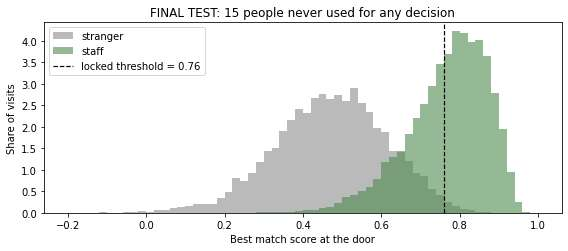

In [69]:
settings = json.loads((MODEL_DIR / "door_settings.json").read_text())   # load the locked settings, don't retype them
THRESHOLD = settings["threshold"]

test_nc = newcomers[newcomers["group"] == "test_newcomer"].reset_index(drop=True)
test_people = test_nc["person"].to_numpy()
test_fps = fingerprints_with(fingerprint_maker_v2, test_nc["path"])
print(f"Test newcomers: {len(np.unique(test_people))} people, {len(test_nc):,} photos")

# Exactly the same door simulation as for validation, but on the 15 TEST newcomers with the LOCKED settings
rng = np.random.default_rng(SEED)

visits_test = pd.concat([door_round_v3(test_fps, test_people, rng,
                                       settings["enrol_photos"], settings["door_photos"]).assign(round=r)
                         for r in range(N_ROUNDS)], ignore_index=True)
visits_test["right_name"] = visits_test["best_match"] == visits_test["person"]

# Headline: validation (where the threshold was chosen) next to test (the honest result)
final = pd.DataFrame({
    "validation newcomers": door_outcomes(visits_val, THRESHOLD),
    "TEST newcomers (final)": door_outcomes(visits_test, THRESHOLD),
}).mul(100).round(1)
print(f"Threshold {THRESHOLD} | {settings['enrol_photos']} enrolment photos | {settings['door_photos']} door photos")
display(final)

# How much the result depends on which people happened to be staff vs strangers (20 rounds)
per_round = pd.DataFrame([door_outcomes(g, THRESHOLD) for _, g in visits_test.groupby("round")]).mul(100)

display(per_round.agg(["min", "mean", "max"]).round(1))

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(-0.2, 1, 61)
ax.hist(visits_test.loc[~visits_test.is_staff, "best_score"], bins=bins, density=True, alpha=0.6, color=GREY, label="stranger")
ax.hist(visits_test.loc[visits_test.is_staff, "best_score"], bins=bins, density=True, alpha=0.6, color=GREEN, label="staff")
ax.axvline(THRESHOLD, color="k", ls="--", lw=1.2, label=f"locked threshold = {THRESHOLD}")
ax.set(xlabel="Best match score at the door", ylabel="Share of visits",
       title="FINAL TEST: 15 people never used for any decision")
ax.legend(); plt.tight_layout(); save_fig("door_final_test"); plt.show()

#### Using the CNN like the bookstore would
---
###### Two functions are all the bookstore needs:
###### - `enrol_staff(name, photos)`: on a new staff member's first day. 10 photos → one master fingerprint, saved under their name. **No retraining.**
###### - `door(photos)`: every time someone walks up. 3 photos → compared with every master fingerprint → "Welcome, name!" or "Please go to reception."

###### For ordinary photos (not the dataset's ready-cropped faces), `find_face=True` first cuts out the face with the same OpenCV face finder used in the EDA, so the CNN sees the same kind of tight crop it was trained on.

##### HELPER functions

In [70]:
DOOR = json.loads((MODEL_DIR / "door_settings.json").read_text()) # the locked settings
FACE_FINDER = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

def read_photo(path, find_face=False, margin=0.25):
    """Load a photo as RGB. With find_face=True, cut out the biggest face (plus a margin for hair and chin)."""
    img = cv2.imread(str(path))
    if img is None:
        return None
    if find_face:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        faces = FACE_FINDER.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
        if len(faces) == 0:
            return None  # no face: the door asks the person to try again
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3]) # the biggest face = the person closest to the camera
        m = int(margin * w)
        img = img[max(0, y - m):y + h + m, max(0, x - m):x + w + m]
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def fingerprint_of(images):
    """Several photos of ONE person -> one averaged fingerprint (length 1)."""
    batch = tf.stack([tf.image.resize(im, [IMG_SIZE, IMG_SIZE], antialias=True) for im in images])  # same resize as training
    fps = fingerprint_maker_v2.predict(batch, verbose=0)
    fps = fps / np.linalg.norm(fps, axis=1, keepdims=True)
    avg = fps.mean(axis=0)
    return avg / np.linalg.norm(avg)

##### `enrol_staff` & `door` in use

In [71]:
gallery = {} # name -> master fingerprint. This dictionary IS the staff list.

def enrol_staff(name, photo_paths, find_face=False):
    images = [im for im in (read_photo(p, find_face) for p in photo_paths) if im is not None]
    if not images:
        print(f"  Could not enrol {name}: no face found in any photo")
        return
    if len(images) < DOOR["enrol_photos"]:
        print(f"  Warning: only {len(images)} usable photos for {name} (the door was tuned with {DOOR['enrol_photos']})")
    gallery[name] = fingerprint_of(images)
    print(f"Enrolled {name} from {len(images)} photos")

def door(photo_paths, find_face=False):
    """Returns (message, matched name or None, best score)."""
    images = [im for im in (read_photo(p, find_face) for p in photo_paths) if im is not None]
    if not images:
        return "No face found - please look straight at the camera and try again", None, None
    fp = fingerprint_of(images)
    names = list(gallery)
    scores = np.stack([gallery[n] for n in names]) @ fp # visitor against every staff member
    best = int(scores.argmax())
    if scores[best] >= DOOR["threshold"]:
        return f"Welcome, {names[best]}!", names[best], float(scores[best])
    return "Please go to reception.", None, float(scores[best])

##### DEMO on test NewComers

Enrolled Sarah Wayne Callies from 10 photos
Enrolled Katherine Langford from 10 photos
Enrolled Maria Pedraza from 10 photos


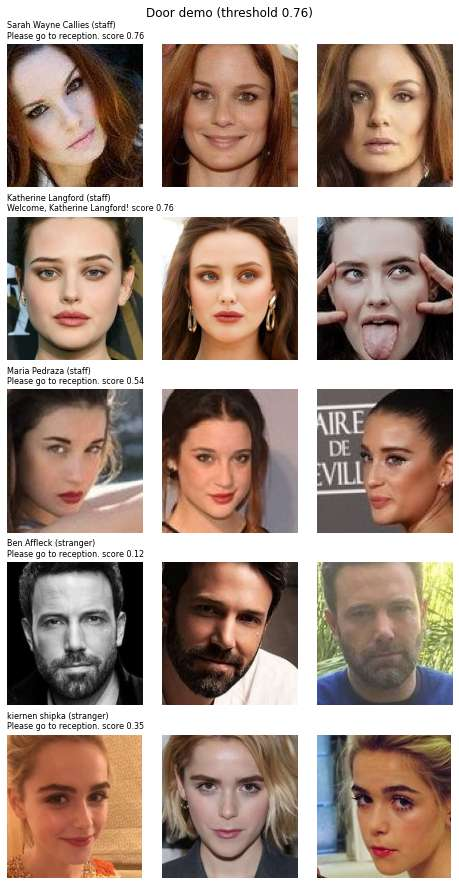

In [72]:
test_nc = newcomers[newcomers["group"] == "test_newcomer"]
demo_rng = np.random.default_rng(SEED)
demo_people = demo_rng.choice(sorted(test_nc["person"].unique()), size=5, replace=False)
demo_staff, demo_strangers = demo_people[:3], demo_people[3:] # 3 staff, 2 strangers

gallery.clear()
door_paths = {}
for person in demo_people:
    paths = demo_rng.permutation(test_nc.loc[test_nc["person"] == person, "path"].to_numpy())
    if person in demo_staff:
        enrol_staff(person, paths[:DOOR["enrol_photos"]]) # first-day photos
    door_paths[person] = paths[DOOR["enrol_photos"]:DOOR["enrol_photos"] + DOOR["door_photos"]] # different photos at the door

fig, axes = plt.subplots(len(demo_people), DOOR["door_photos"],
                         figsize=(2.2 * DOOR["door_photos"], 2.5 * len(demo_people)))
for row, person in zip(axes, demo_people):
    message, who, score = door(door_paths[person])
    truth = "staff" if person in demo_staff else "stranger"
    for ax, p in zip(row, door_paths[person]):
        ax.imshow(read_photo(p)); ax.axis("off")
    row[0].set_title(f"{person} ({truth})\n{message} score {score:.2f}", fontsize=8, loc="left")
plt.suptitle(f"Door demo (threshold {DOOR['threshold']})"); plt.tight_layout()
save_fig("door_demo"); plt.show()

#### ERROR ANALYSIS (test newcomers)
###### 1. **Who** does the door struggle with? Per-person welcome rate, and which strangers were mistaken for which staff.
###### 2. **Which photos** are hard? Every test photo is scored against its own person's template (10 other photos). Are side profiles, black-and-white, very dark or blurry photos (flagged in the EDA) scored lower than the rest?

##### WHO the door struggels with

In [73]:
staff_v = visits_test[visits_test["is_staff"]]
per_person = (staff_v.assign(welcomed=(staff_v["best_score"] >= DOOR["threshold"]) & staff_v["right_name"])
              .groupby("person")["welcomed"].mean().mul(100).round(1).sort_values())
print("Share of door visits welcomed, per person (when they were staff):")
print(per_person.to_string())

strangers_in = visits_test[~visits_test["is_staff"] & (visits_test["best_score"] >= DOOR["threshold"])]
print(f"\nStrangers let in: {len(strangers_in)} visits. Who was mistaken for whom:")
display(strangers_in.groupby(["person", "best_match"]).size().rename("times let in")
        .sort_values(ascending=False).head(10).to_frame())

Share of door visits welcomed, per person (when they were staff):
person
Maria Pedraza             23.3
Tom Hiddleston            23.7
Emma Stone                31.1
Sarah Wayne Callies       32.2
Jason Momoa               35.6
Ben Affleck               52.2
Emilia Clarke             59.2
Jennifer Lawrence         61.1
Tom Cruise                66.0
Katherine Langford        71.3
Krysten Ritter            75.6
jeff bezos                83.1
kiernen shipka            87.5
Chris Hemsworth           90.8
Shakira Isabel Mebarak    91.7

Strangers let in: 93 visits. Who was mistaken for whom:


,,times let in
person,best_match,
Chris Hemsworth,Tom Cruise,46
Tom Cruise,Chris Hemsworth,30
Ben Affleck,Chris Hemsworth,4
Katherine Langford,Maria Pedraza,4
Emilia Clarke,Katherine Langford,2
Jason Momoa,Chris Hemsworth,2
Emilia Clarke,kiernen shipka,1
Jennifer Lawrence,Emilia Clarke,1
Emma Stone,Jennifer Lawrence,1


<img src="selfies/SpiderMan.png" width="420">

##### What KIND of image was hard to depict?

,photos,avg own score (flagged),avg own score (the rest)
side profile (no frontal face found),207.0,0.477,0.618
black-and-white,168.0,0.557,0.609
very dark,12.0,0.425,0.607
blurriest 10%,198.0,0.573,0.609


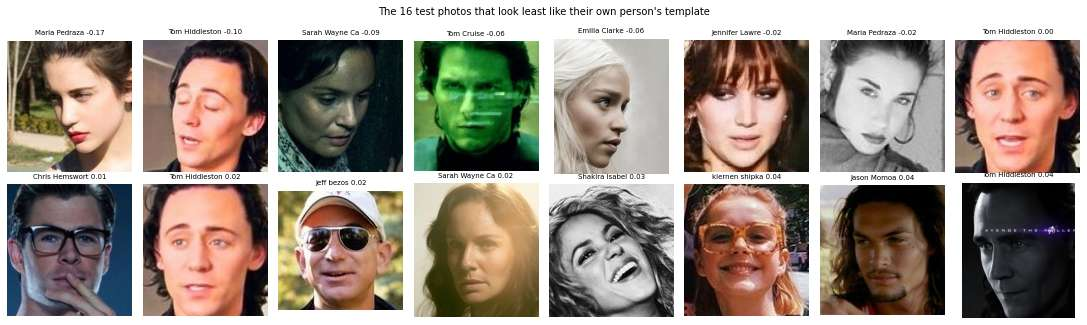

In [74]:
meta_flags = pd.read_csv(DATA_DIR / "meta.csv")[["path", "colourfulness", "brightness", "sharpness", "n_faces"]]
blur_cut = meta_flags["sharpness"].quantile(0.10) # "blurry" = the blurriest 10% of the whole dataset

# Every test photo against its own person's template (built from 10 OTHER photos of them)
rng = np.random.default_rng(SEED)
test_paths = test_nc["path"].to_numpy()
rows = []
for person in np.unique(test_people):
    idx = rng.permutation(np.flatnonzero(test_people == person))
    enrol_idx, rest = idx[:DOOR["enrol_photos"]], idx[DOOR["enrol_photos"]:]
    template = test_fps[enrol_idx].mean(axis=0)
    template /= np.linalg.norm(template)
    rows.append(pd.DataFrame({"path": test_paths[rest], "person": person, "own_score": test_fps[rest] @ template}))
photo_scores = pd.concat(rows, ignore_index=True).merge(meta_flags, on="path", how="left")

checks = {
    "side profile (no frontal face found)": photo_scores["n_faces"] == 0,
    "black-and-white":                      photo_scores["colourfulness"] < 2,
    "very dark":                            photo_scores["brightness"] < 40,
    "blurriest 10%":                        photo_scores["sharpness"] < blur_cut,
}
quality = pd.DataFrame({
    name: {"photos": int(mask.sum()),
           "avg own score (flagged)": photo_scores.loc[mask, "own_score"].mean(),
           "avg own score (the rest)": photo_scores.loc[~mask, "own_score"].mean()}
    for name, mask in checks.items()
}).T.round(3)
display(quality)

worst = photo_scores.nsmallest(16, "own_score")
show_grid(worst["path"], titles=[f"{p[:14]} {s:.2f}" for p, s in zip(worst["person"], worst["own_score"])],
          ncols=8, suptitle="The 16 test photos that look least like their own person's template",
          save="error_worst_photos")

#### RESULTS SUMMARY

<div style="font-size: 0.7em">

| Step | Change | Staff welcomed (strangers ≤ 1%) |
|---|---|---|
| CNN v1 | Softmax name picker | 5.1% |
| Fix 1 | Centre the fingerprints | 6.3% (no real help) |
| Fix 2: CNN v2 | Cosine + margin (staff test accuracy 75% → 89%) | 15.8% |
| Door settings | Enrol 10 photos, judge 3 per visit | 52.0% |

</div>

#### FINAL TEST (15 people never used for any decision)

<div style="font-size: 0.7em">

| Staff welcomed (right name) | Staff welcomed (wrong name) | Staff sent to reception | Strangers let in |
|---|---|---|---|
| **59.1%** | 0.3% | 40.6% | **1.2%** (target ≤ 1%) |

</div>

#### KEY FINDINGS
- The threshold carried over to new people: tuned for 1% of strangers, it let in 1.2%.
- 82% of stranger mistakes were one look-alike pair (Chris Hemsworth and Tom Cruise).
- Side-profile photos are the hardest. A real door should ask people to look at the camera.
- Next step: a pretrained network instead of training from scratch.